# Step 3 — Which live games will lose half their players? (main analysis)

**Research question.** Given 90 days of Steam player counts, Twitch attention and store metadata, can we predict whether a live game will **lose at least half of its players relative to the Steam market** over the next 6–12 months?

**Why relative, and why relative to the market.**

- The first version asked whether a game stays above 10 players. That was answered by today's player count and could never flag a big game in trouble.
- The second version asked whether a game loses half of its own players. That works for every size, but the share of games doing so swung from 20% (2018) to 3% (2020) with the whole market, so its probabilities were unusable from one year to the next.
- This version asks whether a game ends up **below half of where the typical live game ends up**. When the whole market falls 20%, a game must fall to less than 0.5 × 0.8 = 40% of its level to count. A market-wide boom or slump no longer changes what counts as a collapse.

**What else is new.**

- **Many start dates.** The model learns from every monthly start date whose outcome is already known (Dec 2017 – Aug 2019), not from one date.
- **Monthly backtest.** It is tested every month from Jan to Aug 2019, always trained only on outcomes known by then.
- **Calibrated probabilities.** The score is a real probability: among games scored around 20%, about one in five should collapse.
- **Explained flags.** Every scored game gets its three main reasons in plain language.

**Population.** Live games: at least 10 average players in the 90-day window.

**Contents**

1. Load data, build features (unchanged)
2. Monthly start dates and the market-relative target
3. Exploration
4. Models vs baselines (Feb 2019 test)
5. Monthly backtest: does training on many start dates help, and are the probabilities right?
6. Big games and launch-stage games
7. Does Twitch help? Ablation and importance
8. Robustness: decline threshold, size of the change
9. Explaining each flag
10. Deliverable: watch lists with reasons, for the report and the website

In [1]:
from pathlib import Path
import csv
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, brier_score_loss, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
STEAM_DIR = PROJECT_ROOT / "data" / "steam-games-dataset"
SULLY_DIR = PROJECT_ROOT / "data" / "sullygnome"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures" / "decline"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_DAYS = 90                      # features: days [origin, origin + 90)
TARGET_START, TARGET_END = 180, 365    # target: days [origin + 180, origin + 365]
MIN_FEATURE_DAYS, MIN_TARGET_DAYS = 60, 150
MIN_PLAYERS = 10                       # population: live games with >= 10 average players in the feature window
DECLINE_RATIO = 0.5                    # "collapse" = relative change vs the market below 50%
WATCHLIST_SHARE = 0.10                 # the product flags the riskiest 10% of the catalogue
HORIZON_MONTHS = (TARGET_START + TARGET_END) / 2 / 30.4 - FEATURE_DAYS / 2 / 30.4  # mid-window to mid-window
RANDOM_STATE = 42

SIZE_BANDS = [10, 100, 1000, np.inf]
SIZE_LABELS = ["10–100 players", "100–1,000 players", "1,000+ players"]

COLORS = {"decline": "#d1495b", "stable": "#2a7ab9", "neutral": "#8c8c8c", "accent": "#edae49", "dark": "#30343f"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png")
    print(f"Saved reports/figures/decline/{name}.png")

## 1. Load data and build features

In [2]:
panel = pd.read_parquet(PROCESSED_DIR / "steam_daily_panel.parquet",
                        columns=["appid", "date", "mean_player_count", "median_player_count", "max_player_count"])
summary = pd.read_csv(PROCESSED_DIR / "steam_game_summary.csv", parse_dates=["first_observed", "last_observed", "releasedate"])
twitch = pd.read_csv(SULLY_DIR / "twitch_monthly_by_appid.csv")
twitch["month_ord"] = pd.PeriodIndex(twitch["month"], freq="M").map(lambda p: p.year * 12 + p.month)
twitch_mapped_ids = set(pd.read_csv(SULLY_DIR / "appid_map_validated.csv")["appid"])
DATA_START, DATA_END = panel["date"].min(), panel["date"].max()


def read_multi(filename, value_name):
    """Read the wide 'appid,value1,value2,...' files; csv.reader keeps quoted names like "Psyonix, Inc." intact."""
    rows = []
    with (STEAM_DIR / filename).open(encoding="cp1252", newline="") as file:
        for record in csv.reader(file):
            values = [value.strip() for value in record if value.strip()]
            if len(values) > 1 and values[0].isdigit():
                rows.extend((int(values[0]), value) for value in values[1:])
    return pd.DataFrame(rows, columns=["appid", value_name]).drop_duplicates()


genres, tags = read_multi("applicationGenres.csv", "genre"), read_multi("applicationTags.csv", "tag")
languages, packages = read_multi("applicationSupportedlanguages.csv", "language"), read_multi("applicationPackages.csv", "package")
developers, publishers = read_multi("applicationDevelopers.csv", "developer"), read_multi("applicationPublishers.csv", "publisher")
games = summary[summary["type"].eq("game")].copy()


def multi_hot(long, column, min_games, prefix, top=None):
    long = long[long["appid"].isin(games["appid"])]
    counts = long[column].value_counts()
    keep = counts[counts >= min_games].index
    if top:
        keep = keep[:top]
    wide = pd.crosstab(long["appid"], long[column]).reindex(columns=keep).clip(upper=1)
    wide.columns = [f"{prefix}{value.lower().replace(' ', '_').replace('-', '_')}" for value in wide.columns]
    return wide


genre_onehot, tag_onehot = multi_hot(genres, "genre", 25, "genre_"), multi_hot(tags, "tag", 100, "tag_", top=20)
GENRE_COLUMNS, TAG_COLUMNS = list(genre_onehot.columns), list(tag_onehot.columns)
main_publisher = publishers.groupby("appid")["publisher"].first()
publisher_size = main_publisher.map(main_publisher[main_publisher.index.isin(games["appid"])].value_counts())
static = (
    games[["appid", "name", "releasedate", "freetoplay"]].set_index("appid")
    .join(genre_onehot).join(tag_onehot)
    .join(tags.groupby("appid").size().rename("n_tags"))
    .join(languages.groupby("appid").size().rename("n_languages"))
    .join(packages.groupby("appid").size().rename("n_packages"))
    .join(developers.groupby("appid").size().rename("n_developers"))
    .join(main_publisher.rename("publisher"))
    .join(np.log1p(publisher_size).rename("log_publisher_catalog"))
)
static[GENRE_COLUMNS + TAG_COLUMNS] = static[GENRE_COLUMNS + TAG_COLUMNS].fillna(0)
static["freetoplay_unknown"] = static["freetoplay"].isna().astype(int)
static["twitch_mapped"] = static.index.isin(twitch_mapped_ids).astype(int)
static["group"] = static["publisher"].fillna(pd.Series("appid_" + static.index.astype(str), index=static.index))
print(f"Games: {len(static):,}; static features: {len(GENRE_COLUMNS)} genres, {len(TAG_COLUMNS)} tags, counts, publisher size")

Games: 1,851; static features: 12 genres, 20 tags, counts, publisher size


Features are computed per game from its own **origin date** (most analyses use one shared date; the launch-stage check in Section 5 uses each game's release date). Feature definitions are the same as in the floor model: 8 Steam-activity, 7 Twitch and 42 metadata features.

In [3]:
STEAM_FEATURES = ["log_early_mean", "log_peak_to_mean", "volatility", "trend_log_per_30d",
                  "last_vs_first_month", "weekend_uplift", "low_day_share", "log_early_min"]
TWITCH_FEATURES = ["log_twitch_avg_viewers", "log_twitch_peak_viewers", "log_twitch_view_minutes",
                   "log_twitch_avg_channels", "twitch_months_in_top", "twitch_viewers_per_player", "twitch_mapped"]
META_FEATURES = (["age_years", "early_access", "release_unknown", "freetoplay", "freetoplay_unknown",
                  "n_tags", "n_languages", "n_packages", "n_developers", "log_publisher_catalog"]
                 + GENRE_COLUMNS + TAG_COLUMNS)
ALL_FEATURES = META_FEATURES + STEAM_FEATURES + TWITCH_FEATURES
FEATURE_GROUPS = {"Metadata": META_FEATURES, "Steam activity": STEAM_FEATURES, "Twitch": TWITCH_FEATURES}


def with_offset(frame, origins):
    frame = frame.merge(origins.rename("origin"), left_on="appid", right_index=True)
    frame["t"] = (frame["date"] - frame["origin"]).dt.days
    return frame


def steam_window_features(origins):
    window = with_offset(panel, origins)
    window = window[window["t"].between(0, FEATURE_DAYS - 1)].copy()
    window["y"] = np.log1p(window["mean_player_count"])
    window["ty"], window["tt"] = window["t"] * window["y"], window["t"] ** 2
    window["weekend"] = window["date"].dt.dayofweek >= 5
    out = window.groupby("appid").agg(
        feature_days=("date", "nunique"), early_mean=("mean_player_count", "mean"), early_std=("mean_player_count", "std"),
        early_peak=("max_player_count", "max"), early_min=("mean_player_count", "min"),
        low_day_share=("median_player_count", lambda values: values.le(1).mean()),
        t=("t", "mean"), y=("y", "mean"), ty=("ty", "mean"), tt=("tt", "mean"))
    out["log_early_mean"] = np.log1p(out["early_mean"])
    out["log_peak_to_mean"] = np.log1p(out["early_peak"]) - out["log_early_mean"]
    out["volatility"] = out["early_std"] / (out["early_mean"] + 1)
    out["trend_log_per_30d"] = 30 * (out["ty"] - out["t"] * out["y"]) / (out["tt"] - out["t"] ** 2)
    first = window[window["t"] < 30].groupby("appid")["y"].mean()
    last = window[window["t"] >= FEATURE_DAYS - 30].groupby("appid")["y"].mean()
    out["last_vs_first_month"] = last - first
    weekend = window.groupby(["appid", "weekend"])["y"].mean().unstack()
    out["weekend_uplift"] = weekend.get(True) - weekend.get(False)
    out["log_early_min"] = np.log1p(out["early_min"])
    return out[["feature_days", "early_mean"] + STEAM_FEATURES]


def twitch_window_features(origins):
    o = origins.rename("origin").to_frame()
    o["start_ord"] = o["origin"].dt.year * 12 + o["origin"].dt.month
    end = o["origin"] + pd.Timedelta(days=FEATURE_DAYS - 1)
    o["n_months"] = end.dt.year * 12 + end.dt.month - o["start_ord"] + 1
    window = twitch.merge(o, left_on="appid", right_index=True)
    window = window[window["month_ord"].between(window["start_ord"], window["start_ord"] + window["n_months"] - 1)]
    grouped = window.groupby("appid")
    months = o["n_months"]
    out = pd.DataFrame({
        # Months outside the top 2,000 count as 0, so sums are divided by the number of months in the window.
        "avg_viewers": grouped["avgviewers"].sum() / months, "peak_viewers": grouped["maxviewers"].max(),
        "view_minutes": grouped["viewminutes"].sum(), "avg_channels": grouped["avgchannels"].sum() / months,
        "twitch_months_in_top": grouped["month"].nunique(),
    }).reindex(grouped.size().index)
    return pd.DataFrame({
        "log_twitch_avg_viewers": np.log1p(out["avg_viewers"]), "log_twitch_peak_viewers": np.log1p(out["peak_viewers"]),
        "log_twitch_view_minutes": np.log1p(out["view_minutes"]), "log_twitch_avg_channels": np.log1p(out["avg_channels"]),
        "twitch_months_in_top": out["twitch_months_in_top"],
    })


def target_window(origins):
    window = with_offset(panel[["appid", "date", "mean_player_count"]], origins)
    window = window[window["t"].between(TARGET_START, TARGET_END)]
    return window.groupby("appid").agg(future_mean=("mean_player_count", "mean"), target_days=("date", "nunique"))


def build_dataset(origins, labelled=True):
    """origins: Series appid -> origin date (one shared date, or one per game)."""
    origins = origins[origins.index.isin(static.index)]
    data = static.join(origins.rename("origin"), how="inner").join(steam_window_features(origins), how="inner")
    data = data.join(twitch_window_features(origins))
    twitch_columns = [c for c in TWITCH_FEATURES if c not in ("twitch_viewers_per_player", "twitch_mapped")]
    data[twitch_columns] = data[twitch_columns].fillna(0)
    data["twitch_viewers_per_player"] = data["log_twitch_avg_viewers"] - data["log_early_mean"]
    data["age_years"] = (data["origin"] - data["releasedate"]).dt.days / 365.25
    data["early_access"] = (data["age_years"] < 0).astype(int)
    data["release_unknown"] = data["releasedate"].isna().astype(int)
    data["age_years"] = data["age_years"].clip(lower=0)
    data = data[(data["feature_days"] >= MIN_FEATURE_DAYS) & (data["early_mean"] >= MIN_PLAYERS)]
    data["size_band"] = pd.cut(data["early_mean"], SIZE_BANDS, right=False, labels=SIZE_LABELS)
    if labelled:
        data = data.join(target_window(origins), how="inner")
        data = data[data["target_days"] >= MIN_TARGET_DAYS]
        data["change_ratio"] = data["future_mean"] / data["early_mean"]
        data["log_change"] = np.log((data["future_mean"] + 1) / (data["early_mean"] + 1))
        data["declined"] = data["change_ratio"].lt(DECLINE_RATIO).astype(int)
    return data


def shared(origin):
    return pd.Series(origin, index=static.index)

## 2. Monthly start dates and the market-relative target

One feature/target dataset is built per start date: 14 Dec 2017, then the 1st of every month from Jan 2018 to Aug 2019. Aug 2019 is the last start whose 12-month outcome fits in the data. For each start date:

- **market change** = the median change of all live games between the 90-day window and months 6–12;
- **relative change** = the game's change divided by the market change;
- **collapse** = relative change below one half.

,live_games,market_change,absolute_rate,relative_rate
origin,,,,
2017-12-14,1758,0.745,0.197,0.111
2018-01-01,1722,0.794,0.155,0.096
2018-02-01,1689,0.850,0.135,0.091
2018-03-01,1666,0.898,0.113,0.089
2018-04-01,1637,0.917,0.104,0.084
2018-05-01,1621,0.879,0.106,0.073
2018-06-01,1623,0.870,0.108,0.078
2018-07-01,1622,0.906,0.096,0.071
2018-08-01,1610,0.963,0.076,0.064


Saved reports/figures/decline/fig01_market_and_target.png


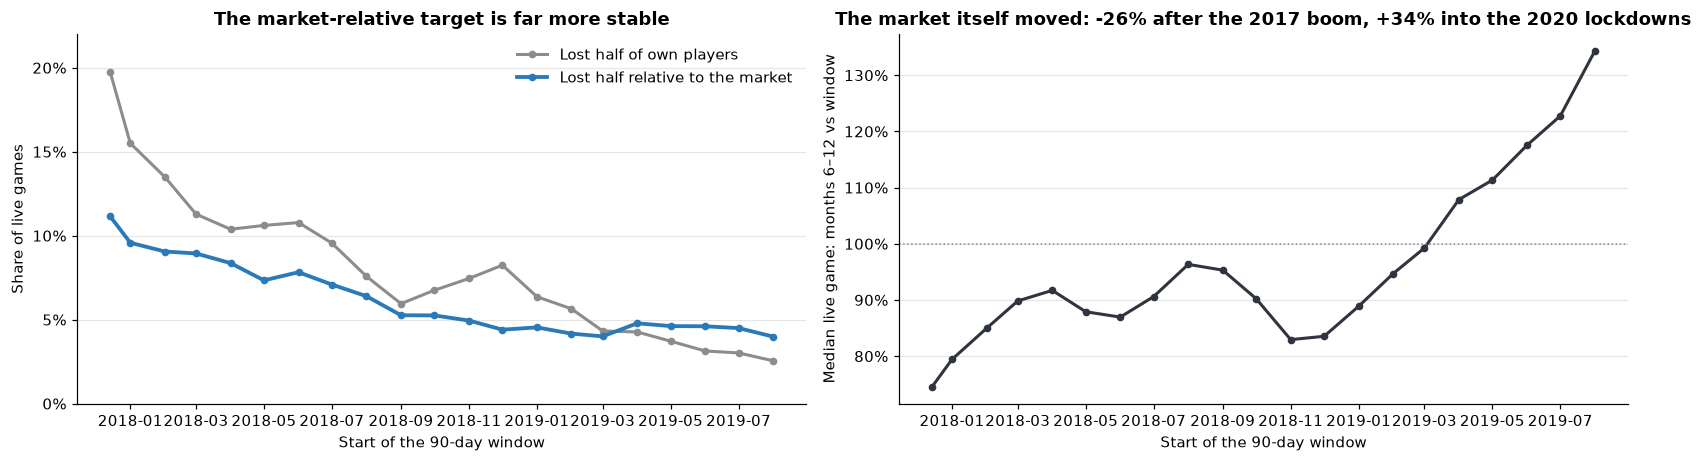

In [4]:
TRAIN_STARTS = [pd.Timestamp("2017-12-14")] + list(pd.date_range("2018-01-01", "2019-08-01", freq="MS"))
HEADLINE_TEST = pd.Timestamp("2019-02-01")
BACKTEST_STARTS = list(pd.date_range("2019-01-01", "2019-08-01", freq="MS"))


def add_targets(data, market_log_change=None):
    market = data["log_change"].median() if market_log_change is None else market_log_change
    data["market_log_change"] = market
    data["relative_log_change"] = data["log_change"] - market
    data["collapsed"] = data["relative_log_change"].lt(np.log(DECLINE_RATIO)).astype(int)
    return data


by_start = {start: add_targets(build_dataset(shared(start))) for start in TRAIN_STARTS}
rows = pd.concat(by_start.values())
starts = pd.DataFrame({
    "live_games": rows.groupby("origin").size(),
    "market_change": np.exp(rows.groupby("origin")["market_log_change"].first()),
    "absolute_rate": rows.groupby("origin")["declined"].mean(),
    "relative_rate": rows.groupby("origin")["collapsed"].mean(),
})
display(starts.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].plot(starts.index, starts["absolute_rate"], color=COLORS["neutral"], lw=2, marker="o", ms=4, label="Lost half of own players")
axes[0].plot(starts.index, starts["relative_rate"], color=COLORS["stable"], lw=2.5, marker="o", ms=4, label="Lost half relative to the market")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].set(ylabel="Share of live games", ylim=(0, 0.22), title="The market-relative target is far more stable")
axes[0].set_yticks(np.arange(0, 0.21, 0.05))
axes[0].legend(frameon=False)
axes[1].plot(starts.index, starts["market_change"], color=COLORS["dark"], lw=2, marker="o", ms=4)
axes[1].axhline(1, color=COLORS["neutral"], ls=":", lw=1)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].set(ylabel="Median live game: months 6–12 vs window", title="The market itself moved: -26% after the 2017 boom, +34% into the 2020 lockdowns")
for ax in axes:
    ax.set_xlabel("Start of the 90-day window")
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
fig.tight_layout()
save(fig, "fig01_market_and_target")
plt.show()

The share of games that **lost half of their own players** fell from 20% to 3% as the market moved. Measured **against the market**, the share is 11% at the start (the 2018 slump after the 2017 boom) and then settles at about 4–5% from autumn 2018 onwards.

The early drift that remains is partly the panel itself: the same games are tracked for 2.7 years, and older games collapse less often. Game age is a feature, and training on many start dates lets the model see every phase.

## 3. Exploration: who collapses? (Dec 2017 start)

group  games   rate  ci_low  ci_high
dimension                                                                        
Size now                 0          10–100 players    800  0.186   0.161    0.215
                         1       100–1,000 players    738  0.046   0.033    0.064
                         2          1,000+ players    220  0.059   0.035    0.098
90-day trend             0            Falling fast    799  0.155   0.132    0.182
                         1          Falling slowly    454  0.046   0.030    0.070
                         2                    Flat    177  0.045   0.023    0.087
                         3                 Growing    328  0.131   0.099    0.172
Game age                 0              < 6 months    306  0.183   0.144    0.230
                         1      6 months – 2 years    546  0.189   0.158    0.224
                         2               2–5 years    543  0.057   0.041    0.080
                         3                5+ years    344  0.009   0.003    0.025
Business model           0            Free to play    339  0.106   0.078    0.144
                         1                    Paid   1412  0.112   0.096    0.129
Genre (several per game) 4                     Rpg    453  0.053   0.036    0.078
                         3                Strategy    520  0.062   0.044    0.086
                         11                 Racing     61  0.066   0.026    0.157
                         8   Massively Multiplayer    187  0.070   0.041    0.115
                         5              Simulation    426  0.077   0.056    0.107
                         9                  Sports     85  0.082   0.040    0.160
                         7            Free To Play    282  0.096   0.067    0.136
                         0                  Action    837  0.115   0.095    0.138
                         2               Adventure    517  0.118   0.093    0.149
                         10           Early Access     82  0.122   0.068    0.210
                         1                   Indie    747  0.174   0.149    0.203
                         6                  Casual    266  0.252   0.203    0.307

Saved reports/figures/decline/fig02_collapse_by_group.png


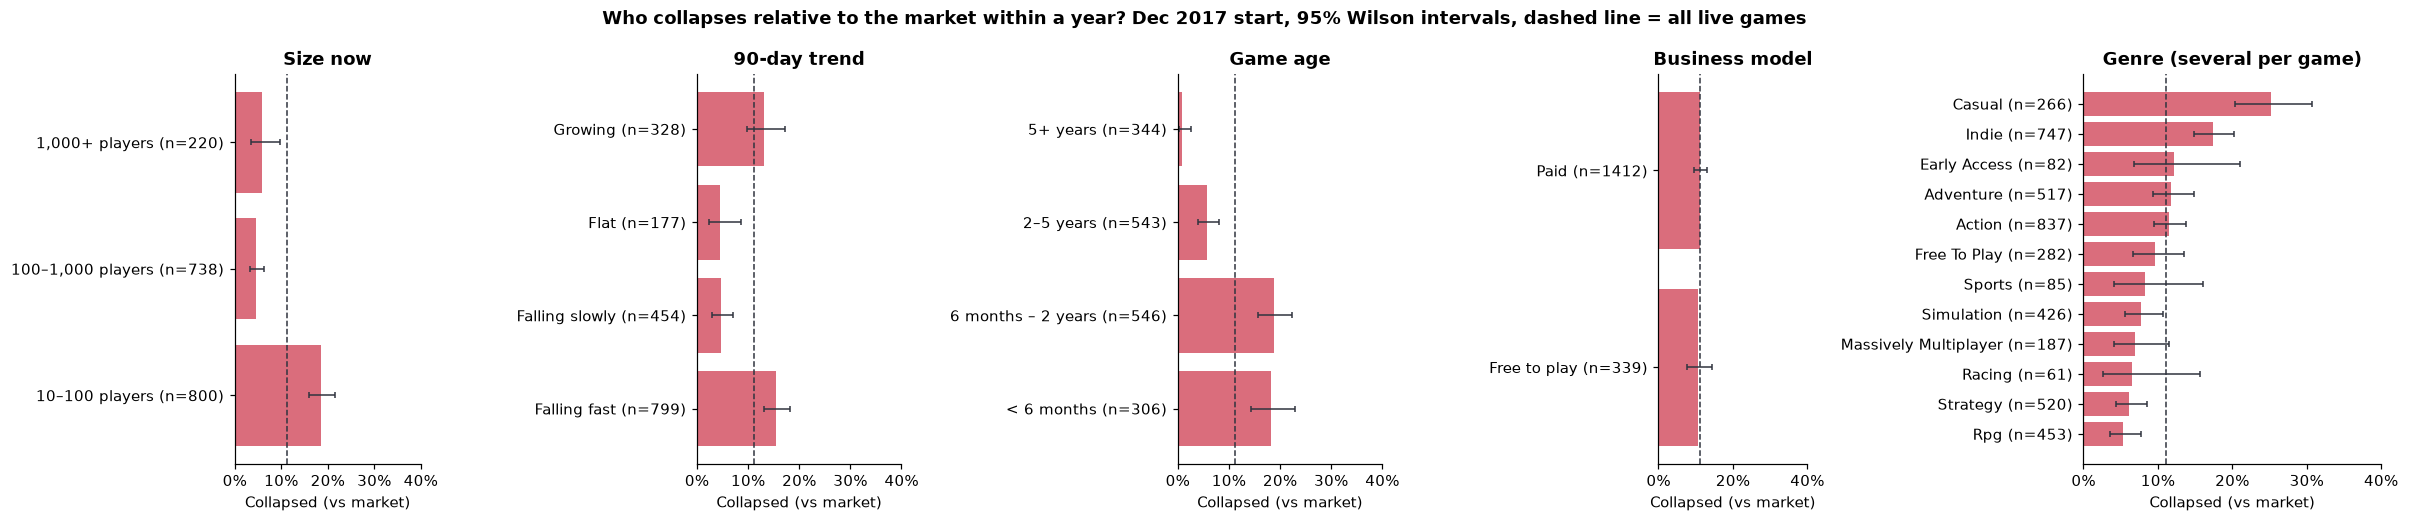

In [5]:
def wilson(successes, n, z=1.96):
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(frame, masks):
    out = []
    for label, mask in masks.items():
        n, k = int(mask.sum()), int(frame.loc[mask, "collapsed"].sum())
        low, high = wilson(k, n)
        out.append({"group": label, "games": n, "rate": k / n, "ci_low": low, "ci_high": high})
    return pd.DataFrame(out)


first = by_start[TRAIN_STARTS[0]]
age_bands = pd.cut(first["age_years"], [-0.01, 0.5, 2, 5, np.inf], labels=["< 6 months", "6 months – 2 years", "2–5 years", "5+ years"])
trend_bands = pd.cut(first["trend_log_per_30d"], [-np.inf, -0.1, -0.02, 0.02, np.inf], labels=["Falling fast", "Falling slowly", "Flat", "Growing"])
groups = {
    "Size now": rate_table(first, {label: first["size_band"].eq(label) for label in SIZE_LABELS}),
    "90-day trend": rate_table(first, {label: trend_bands.eq(label) for label in trend_bands.cat.categories}),
    "Game age": rate_table(first, {label: age_bands.eq(label) for label in age_bands.cat.categories}),
    "Business model": rate_table(first, {"Free to play": first["freetoplay"].eq(1), "Paid": first["freetoplay"].eq(0)}),
    "Genre (several per game)": rate_table(first, {c.replace("genre_", "").replace("_", " ").title(): first[c].eq(1)
                                                   for c in GENRE_COLUMNS if first[c].sum() >= 30}).sort_values("rate"),
}
display(pd.concat(groups, names=["dimension"]).round(3))

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8), gridspec_kw={"width_ratios": [1, 1.1, 1.1, 0.8, 1.6]})
for ax, (title, table) in zip(axes, groups.items()):
    y = np.arange(len(table))
    ax.barh(y, table["rate"], color=COLORS["decline"], alpha=0.8)
    ax.errorbar(table["rate"], y, xerr=[table["rate"] - table["ci_low"], table["ci_high"] - table["rate"]],
                fmt="none", ecolor=COLORS["dark"], lw=1, capsize=2)
    ax.set_yticks(y, [f"{g} (n={n})" for g, n in zip(table["group"], table["games"])])
    ax.axvline(first["collapsed"].mean(), color=COLORS["dark"], ls="--", lw=1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, max(0.4, table["ci_high"].max() * 1.05))
    ax.set_title(title)
    ax.set_xlabel("Collapsed (vs market)")
fig.suptitle("Who collapses relative to the market within a year? Dec 2017 start, 95% Wilson intervals, dashed line = all live games",
             fontweight="bold")
fig.tight_layout()
save(fig, "fig02_collapse_by_group")
plt.show()

Against the market, **young games** (under 2 years: 18–19%) and **small games** (10–100 players: 19%) collapse most often. Games over five years old almost never do (1%). As before, **growing games collapse nearly as often as fast-falling ones** (13% vs 16%), because spikes fade. Casual (25%) and Indie (17%) games are the riskiest genres; free-to-play makes no difference (11% each).

## 4. Models vs baselines (Feb 2019 test)

**Training data.** Every start date whose outcome was complete by 1 Feb 2019: 14 Dec 2017, 1 Jan 2018 and 1 Feb 2018. The same game appears once per start date, so cross-validation groups rows **by publisher**: a game, and its publisher's other games, never sit on both sides of a split.

**Candidates.**

| Name | Score (higher = more likely to collapse) | Flags a collapse when |
|---|---|---|
| No change (persistence) | constant | never |
| Trend rule | minus the 90-day trend | the trend, extended to the outcome window, loses half |
| Age rule | minus the game's age | the game is under one year old |
| Logistic regression / random forest / gradient boosting | calibrated probability | probability ≥ the training collapse rate |

**Model choice.** The previous version picked the random forest by grouped CV, and we keep it as the fixed model family. In this version's CV, logistic regression and the forest are within one standard deviation of each other. The forest also allows exact per-game explanations (Section 9). All three models are reported on the test set.

Every ML model is **calibrated**: a sigmoid fitted on publisher-grouped out-of-fold predictions turns its score into a probability. Ranking quality is unchanged.

In [6]:
TREND_CUTOFF = np.log(DECLINE_RATIO) / HORIZON_MONTHS
BASELINES = ["No change (persistence)", "Trend rule", "Age rule"]
ML_MODELS = ["Logistic regression", "Random forest", "Gradient boosting"]
CANDIDATES = BASELINES + ML_MODELS


def make_model(kind):
    imputer = ("impute", SimpleImputer(strategy="median", keep_empty_features=True))
    if kind == "Logistic regression":
        return Pipeline([imputer, ("scale", StandardScaler()), ("model", LogisticRegression(C=0.3, max_iter=5000, class_weight="balanced"))])
    if kind == "Random forest":
        return Pipeline([imputer, ("model", RandomForestClassifier(
            n_estimators=500, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE))])
    if kind == "Gradient boosting":
        return Pipeline([imputer, ("model", HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0,
            class_weight="balanced", random_state=RANDOM_STATE))])
    raise ValueError(kind)


def grouped_splits(frame, target="collapsed", n_splits=5):
    return list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
                .split(frame, frame[target], groups=frame["group"]))


def fit_calibrated(kind, frame, target="collapsed", features=ALL_FEATURES):
    """One model fitted on all rows + a sigmoid fitted on its publisher-grouped out-of-fold scores."""
    return CalibratedClassifierCV(make_model(kind), method="sigmoid", cv=grouped_splits(frame, target),
                                  ensemble=False).fit(frame[features], frame[target])


def scores_for(name, fitted, frame, features=ALL_FEATURES):
    if name == "No change (persistence)":
        return np.zeros(len(frame))
    if name == "Trend rule":
        return -frame["trend_log_per_30d"].fillna(0).to_numpy()
    if name == "Age rule":
        return -frame["age_years"].fillna(frame["age_years"].median()).to_numpy()
    return fitted.predict_proba(frame[features])[:, 1]


def labels_for(name, scores, base_rate):
    if name == "No change (persistence)":
        return np.zeros(len(scores), dtype=int)
    if name == "Trend rule":
        return (scores > -TREND_CUTOFF).astype(int)
    if name == "Age rule":
        return (scores > -1).astype(int)
    return (scores >= base_rate).astype(int)


def top_share(y, scores, share=WATCHLIST_SHARE):
    k = max(1, int(np.ceil(share * len(y))))
    order = np.argsort(-scores, kind="stable")[:k]
    return y[order].mean(), y[order].sum() / max(1, y.sum())


def metrics(y, scores, predicted):
    constant = len(np.unique(scores)) == 1
    watch_precision, watch_recall = (y.mean(), WATCHLIST_SHARE) if constant else top_share(y, scores)
    return {
        "roc_auc": 0.5 if constant else roc_auc_score(y, scores),
        "avg_precision": y.mean() if constant else average_precision_score(y, scores),
        "watchlist_precision": watch_precision, "watchlist_lift": watch_precision / y.mean(), "watchlist_recall": watch_recall,
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, zero_division=0), "recall": recall_score(y, predicted, zero_division=0),
    }


def bootstrap_ci(y, scores, predicted, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            draws.append(metrics(y[idx], scores[idx], predicted[idx]))
    draws = pd.DataFrame(draws)
    return draws.quantile(0.025), draws.quantile(0.975)


def pool_before(start):
    """All start dates whose 12-month outcome is complete before `start`."""
    return pd.concat([d for s, d in by_start.items() if s + pd.Timedelta(days=TARGET_END) <= start])


train = pool_before(HEADLINE_TEST)
test = by_start[HEADLINE_TEST]
y_train, y_test = train["collapsed"].to_numpy(), test["collapsed"].to_numpy()
print(f"Training rows: {len(train):,} from {train['origin'].nunique()} start dates ({train.index.nunique():,} games); "
      f"collapse rate {y_train.mean():.1%}")

cv_rows = []
for fold, (fit_idx, val_idx) in enumerate(grouped_splits(train)):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    for name in CANDIDATES:
        fitted = make_model(name).fit(fit_part[ALL_FEATURES], fit_part["collapsed"]) if name in ML_MODELS else None
        scores = scores_for(name, fitted, val_part)
        cv_rows.append({"model": name, "fold": fold,
                        **metrics(val_part["collapsed"].to_numpy(), scores, labels_for(name, scores, 0.5))})
cv_results = pd.DataFrame(cv_rows).drop(columns="fold").groupby("model", sort=False).agg(["mean", "std"])
display(cv_results[["roc_auc", "watchlist_precision", "watchlist_lift"]].round(3))
# The model family stays the random forest selected by grouped CV in the previous version (decline vs own players).
# Here logistic regression and the forest are within one CV standard deviation of each other; both are reported on the test.
best_name = "Random forest"
cv_best = cv_results.loc[ML_MODELS, ("roc_auc", "mean")].idxmax()
print(f"Grouped CV AUC: " + ", ".join(f"{m} {cv_results.loc[m, ('roc_auc', 'mean')]:.3f} ± {cv_results.loc[m, ('roc_auc', 'std')]:.3f}" for m in ML_MODELS))
print(f"Highest CV mean: {cv_best}; product model: {best_name} (difference within one standard deviation)")

Training rows: 5,169 from 3 start dates (1,761 games); collapse rate 9.9%


roc_auc        watchlist_precision        watchlist_lift       
                           mean    std                mean    std           mean    std
model                                                                                  
No change (persistence)   0.500  0.000               0.099  0.001          1.000  0.000
Trend rule                0.634  0.091               0.408  0.058          4.101  0.588
Age rule                  0.698  0.042               0.183  0.054          1.837  0.540
Logistic regression       0.928  0.020               0.648  0.059          6.514  0.545
Random forest             0.922  0.020               0.656  0.053          6.592  0.485
Gradient boosting         0.906  0.025               0.627  0.048          6.303  0.449

Grouped CV AUC: Logistic regression 0.928 ± 0.020, Random forest 0.922 ± 0.020, Gradient boosting 0.906 ± 0.025
Highest CV mean: Logistic regression; product model: Random forest (difference within one standard deviation)


In [7]:
fitted_models = {name: fit_calibrated(name, train) for name in ML_MODELS}
best_model = fitted_models[best_name]
test_scores, test_rows = {}, []
for name in CANDIDATES:
    scores = scores_for(name, fitted_models.get(name), test)
    predicted = labels_for(name, scores, y_train.mean())
    test_scores[name] = scores
    low, high = bootstrap_ci(y_test, scores, predicted)
    test_rows.append({"model": name, **metrics(y_test, scores, predicted),
                      **{f"{m}_low": low[m] for m in ["roc_auc", "watchlist_precision", "watchlist_recall"]},
                      **{f"{m}_high": high[m] for m in ["roc_auc", "watchlist_precision", "watchlist_recall"]}})
test_results = pd.DataFrame(test_rows).set_index("model")
print(f"Feb 2019 test: {len(test):,} live games, {y_test.sum()} collapsed ({y_test.mean():.1%}); "
      f"model's average predicted probability {test_scores[best_name].mean():.1%}")
display(test_results.round(3))

Feb 2019 test: 1,559 live games, 65 collapsed (4.2%); model's average predicted probability 4.6%


,roc_auc,avg_precision,watchlist_precision,watchlist_lift,watchlist_recall,balanced_accuracy,precision,recall,roc_auc_low,watchlist_precision_low,watchlist_recall_low,roc_auc_high,watchlist_precision_high,watchlist_recall_high
model,,,,,,,,,,,,,,
No change (persistence),0.500,0.042,0.042,1.000,0.100,0.500,0.000,0.000,0.500,0.032,0.100,0.500,0.052,0.100
Trend rule,0.645,0.331,0.199,4.766,0.477,0.619,0.068,0.585,0.546,0.135,0.342,0.737,0.263,0.583
Age rule,0.578,0.060,0.045,1.076,0.108,0.521,0.088,0.077,0.521,0.019,0.047,0.639,0.090,0.207
Logistic regression,0.811,0.368,0.231,5.535,0.554,0.728,0.297,0.508,0.746,0.167,0.438,0.867,0.301,0.662
Random forest,0.843,0.386,0.269,6.457,0.646,0.717,0.330,0.477,0.778,0.199,0.523,0.902,0.340,0.759
Gradient boosting,0.824,0.368,0.263,6.304,0.631,0.779,0.273,0.631,0.755,0.186,0.500,0.881,0.346,0.740


Saved reports/figures/decline/fig03_model_comparison.png


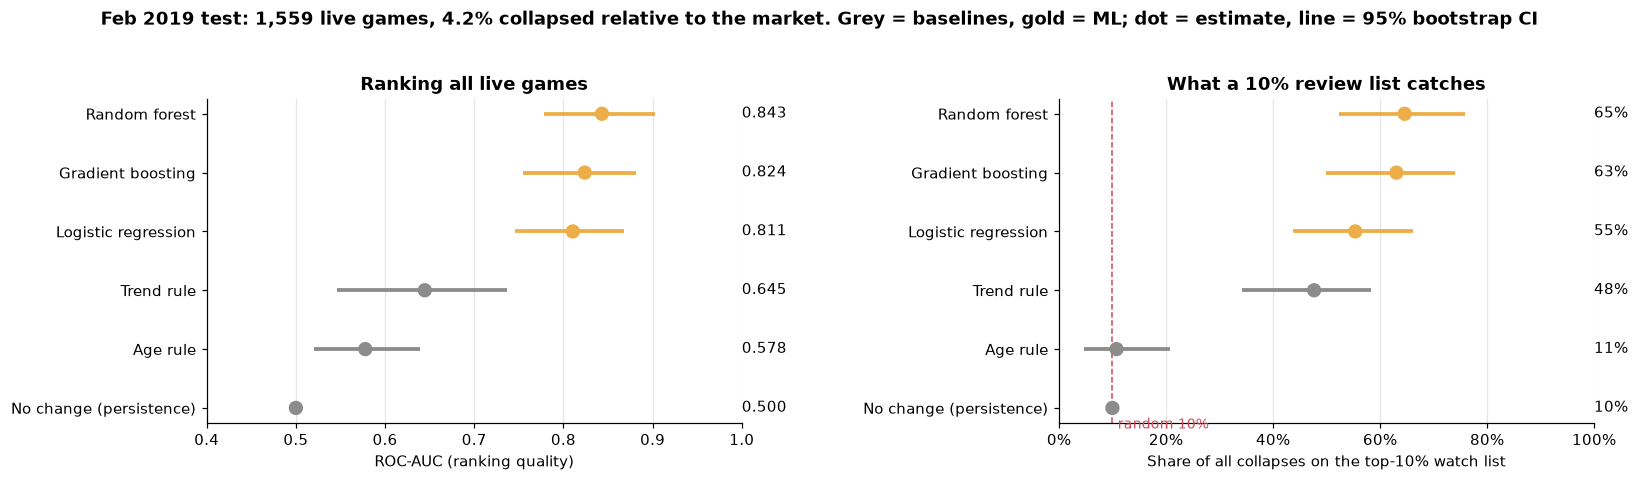

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
panels = [("roc_auc", "roc_auc_low", "roc_auc_high", (0.4, 1.0), "ROC-AUC (ranking quality)", "Ranking all live games"),
          ("watchlist_recall", "watchlist_recall_low", "watchlist_recall_high", (0, 1.0),
           "Share of all collapses on the top-10% watch list", "What a 10% review list catches")]
for ax, (column, low, high, xlim, xlabel, title) in zip(axes, panels):
    table = test_results.sort_values(column)
    y = np.arange(len(table))
    colors = [COLORS["accent"] if n in ML_MODELS else COLORS["neutral"] for n in table.index]
    ax.hlines(y, table[low], table[high], color=colors, lw=2.5)
    ax.scatter(table[column], y, color=colors, s=70, zorder=3)
    for yi, value in zip(y, table[column]):
        ax.text(1.0, yi, f"{value:.0%}" if column != "roc_auc" else f"{value:.3f}", transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=9.5)
    if column == "watchlist_recall":
        ax.axvline(WATCHLIST_SHARE, color=COLORS["decline"], ls="--", lw=1)
        ax.text(WATCHLIST_SHARE + 0.01, -0.35, "random 10%", color=COLORS["decline"], fontsize=9)
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_yticks(y, table.index)
    ax.set_xlim(*xlim)
    ax.grid(axis="x", color="#e5e5e5", lw=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
fig.suptitle(f"Feb 2019 test: {len(test):,} live games, {y_test.mean():.1%} collapsed relative to the market. "
             "Grey = baselines, gold = ML; dot = estimate, line = 95% bootstrap CI", fontweight="bold", y=1.03)
fig.tight_layout(w_pad=5)
save(fig, "fig03_model_comparison")
plt.show()

**Feb 2019 test** (1,559 live games, 65 collapsed against the market, 4.2%):

- **Ranking:** the random forest reaches **ROC-AUC 0.843** (95% CI 0.778–0.902), against 0.645 for the trend rule and 0.578 for the age rule. Logistic regression scores 0.811 and gradient boosting 0.824.
- **Watch list:** the top 10% held **65% of all collapses** (95% CI 52–76%) at 27% precision, 6.5× the base rate. The trend rule's top 10% caught 48%.
- **Probability level:** the average predicted probability is 4.6%, against an actual 4.2%.

## 5. Monthly backtest

Each month from Jan to Aug 2019, the model is retrained on every start date whose outcome was known by then, and it scores that month's live games. Three versions are compared on the same market-relative labels:

- **New:** trained on all known start dates, calibrated (the product);
- **One start date:** trained on Dec 2017 only, as in the previous version;
- **Trend rule:** no training.

Calibration is also checked against the old target (losing half of a game's own players), trained the same way.

In [9]:
backtest_rows, backtest_frames = [], []
first_only = by_start[TRAIN_STARTS[0]]
single_model = fit_calibrated(best_name, first_only)  # previous setup: one start date
for start in BACKTEST_STARTS:
    pool, month = pool_before(start), by_start[start]
    y = month["collapsed"].to_numpy()
    new = fit_calibrated(best_name, pool).predict_proba(month[ALL_FEATURES])[:, 1]
    single = single_model.predict_proba(month[ALL_FEATURES])[:, 1]
    trend = -month["trend_log_per_30d"].fillna(0).to_numpy()
    absolute = fit_calibrated(best_name, pool, target="declined").predict_proba(month[ALL_FEATURES])[:, 1]
    y_abs = month["declined"].to_numpy()
    backtest_rows.append({
        "start": start.date(), "training_starts": pool["origin"].nunique(), "games": len(month), "collapse_rate": y.mean(),
        "auc_new": roc_auc_score(y, new), "auc_one_start": roc_auc_score(y, single), "auc_trend": roc_auc_score(y, trend),
        "watch_recall_new": top_share(y, new)[1], "watch_recall_one_start": top_share(y, single)[1],
        "watch_recall_trend": top_share(y, trend)[1],
        "predicted_rate_relative": new.mean(), "actual_rate_relative": y.mean(),
        "predicted_rate_absolute": absolute.mean(), "actual_rate_absolute": y_abs.mean(),
        "brier_new": brier_score_loss(y, new), "brier_base_rate": brier_score_loss(y, np.full(len(y), pool["collapsed"].mean())),
    })
    backtest_frames.append(pd.DataFrame({"start": start, "y": y, "p": new}))
    print(f"{start.date()} done", flush=True)
backtest = pd.DataFrame(backtest_rows).set_index("start")
display(backtest.round(3))
summary_cols = ["auc_new", "auc_one_start", "auc_trend", "watch_recall_new", "watch_recall_one_start", "watch_recall_trend"]
display(backtest[summary_cols].agg(["mean", "min", "max"]).round(3))

2019-01-01 done


2019-02-01 done


2019-03-01 done


2019-04-01 done


2019-05-01 done


2019-06-01 done


2019-07-01 done


2019-08-01 done


,training_starts,games,collapse_rate,auc_new,auc_one_start,auc_trend,watch_recall_new,watch_recall_one_start,watch_recall_trend,predicted_rate_relative,actual_rate_relative,predicted_rate_absolute,actual_rate_absolute,brier_new,brier_base_rate
start,,,,,,,,,,,,,,,
2019-01-01,2,1586,0.045,0.842,0.837,0.585,0.611,0.597,0.403,0.051,0.045,0.101,0.064,0.038,0.047
2019-02-01,3,1559,0.042,0.843,0.814,0.645,0.646,0.569,0.477,0.046,0.042,0.093,0.056,0.032,0.043
2019-03-01,4,1548,0.040,0.804,0.772,0.623,0.484,0.387,0.355,0.044,0.040,0.082,0.043,0.035,0.042
2019-04-01,5,1547,0.048,0.835,0.778,0.578,0.541,0.419,0.324,0.045,0.048,0.079,0.043,0.038,0.048
2019-05-01,6,1559,0.046,0.801,0.745,0.597,0.528,0.403,0.292,0.053,0.046,0.087,0.037,0.039,0.046
2019-06-01,7,1563,0.046,0.860,0.823,0.611,0.556,0.472,0.361,0.057,0.046,0.089,0.031,0.039,0.046
2019-07-01,8,1556,0.045,0.845,0.808,0.557,0.614,0.543,0.243,0.061,0.045,0.098,0.030,0.036,0.045
2019-08-01,9,1528,0.040,0.842,0.801,0.550,0.508,0.525,0.246,0.045,0.040,0.068,0.026,0.031,0.040


,auc_new,auc_one_start,auc_trend,watch_recall_new,watch_recall_one_start,watch_recall_trend
mean,0.834,0.797,0.593,0.561,0.489,0.338
min,0.801,0.745,0.550,0.484,0.387,0.243
max,0.860,0.837,0.645,0.646,0.597,0.477


Saved reports/figures/decline/fig04_monthly_backtest.png


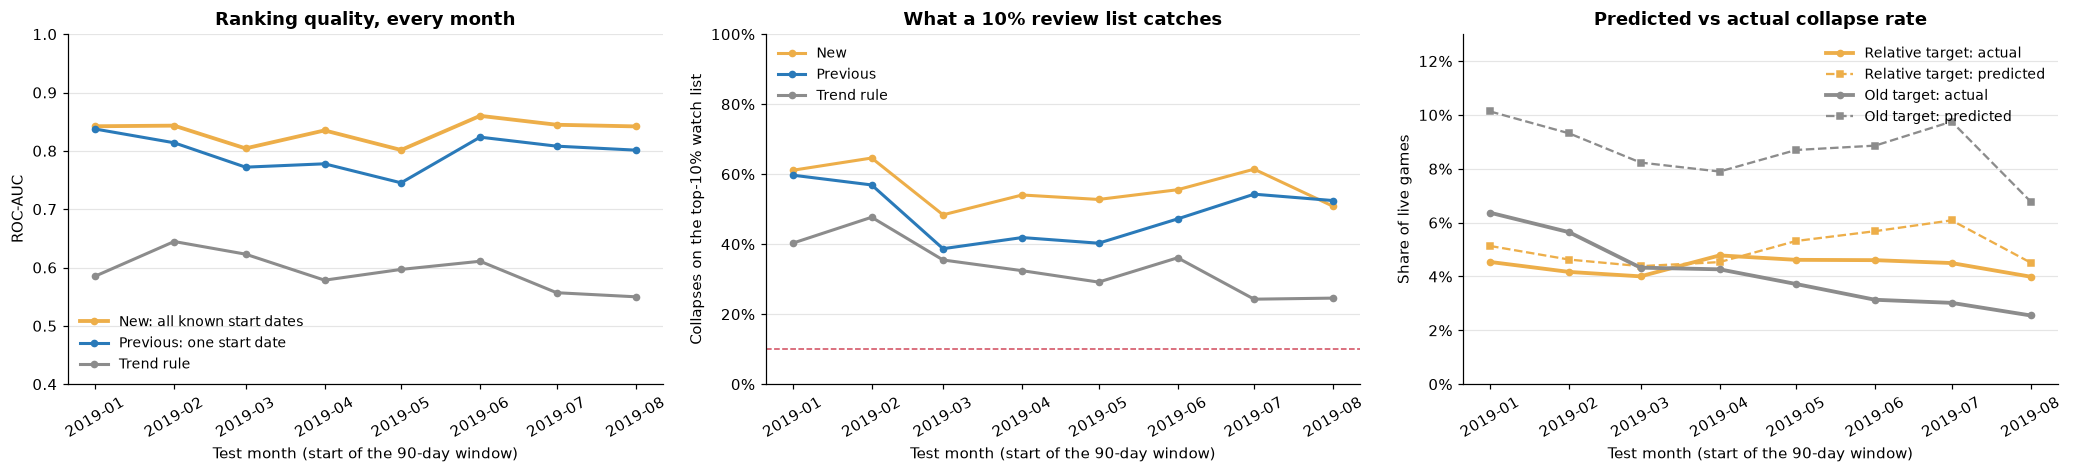

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.4))
x = pd.to_datetime(backtest.index)
for column, color, label, lw in [("auc_new", COLORS["accent"], "New: all known start dates", 2.5),
                                 ("auc_one_start", COLORS["stable"], "Previous: one start date", 2),
                                 ("auc_trend", COLORS["neutral"], "Trend rule", 2)]:
    axes[0].plot(x, backtest[column], color=color, lw=lw, marker="o", ms=4, label=label)
axes[0].set(ylim=(0.4, 1.0), ylabel="ROC-AUC", title="Ranking quality, every month")
axes[0].legend(frameon=False, loc="lower left", fontsize=9)
for column, color, label in [("watch_recall_new", COLORS["accent"], "New"), ("watch_recall_one_start", COLORS["stable"], "Previous"),
                             ("watch_recall_trend", COLORS["neutral"], "Trend rule")]:
    axes[1].plot(x, backtest[column], color=color, lw=2, marker="o", ms=4, label=label)
axes[1].axhline(WATCHLIST_SHARE, color=COLORS["decline"], ls="--", lw=1)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].set(ylim=(0, 1), ylabel="Collapses on the top-10% watch list", title="What a 10% review list catches")
axes[1].legend(frameon=False, loc="upper left", fontsize=9)
axes[2].plot(x, backtest["actual_rate_relative"], color=COLORS["accent"], lw=2.5, marker="o", ms=4, label="Relative target: actual")
axes[2].plot(x, backtest["predicted_rate_relative"], color=COLORS["accent"], lw=1.5, ls="--", marker="s", ms=4, label="Relative target: predicted")
axes[2].plot(x, backtest["actual_rate_absolute"], color=COLORS["neutral"], lw=2.5, marker="o", ms=4, label="Old target: actual")
axes[2].plot(x, backtest["predicted_rate_absolute"], color=COLORS["neutral"], lw=1.5, ls="--", marker="s", ms=4, label="Old target: predicted")
axes[2].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[2].set(ylim=(0, 0.13), ylabel="Share of live games", title="Predicted vs actual collapse rate")
axes[2].legend(frameon=False, fontsize=9, loc="upper right")
for ax in axes:
    ax.set_xlabel("Test month (start of the 90-day window)")
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
save(fig, "fig04_monthly_backtest")
plt.show()

**Over all eight months:**

- **Training on every known start date beats one start date in every month.** Average ROC-AUC is **0.834** (range 0.80–0.86), against 0.797 for one start date and 0.593 for the trend rule. The watch list catches **56%** of collapses on average, against 49% and 34%.
- **Probabilities stay close to reality.** The predicted collapse rate is 4.5–6.1% each month, against an actual 4.0–4.8%. With the old target (losing half of a game's own players) the same model predicted 7–10% while the actual rate fell from 6.4% to 2.6%, up to 3× off.

The market-relative target is what makes probabilities usable from one year to the next.

,games,predicted,actual
p,,,
"(0.019799999999999998, 0.0224]",1245,0.022,0.008
"(0.0224, 0.023]",1245,0.023,0.006
"(0.023, 0.0237]",1244,0.023,0.010
"(0.0237, 0.0246]",1245,0.024,0.010
"(0.0246, 0.026]",1244,0.025,0.018
"(0.026, 0.0282]",1245,0.027,0.019
"(0.0282, 0.0319]",1244,0.030,0.023
"(0.0319, 0.0396]",1245,0.035,0.032
"(0.0396, 0.0656]",1244,0.049,0.068


Saved reports/figures/decline/fig05_calibration.png


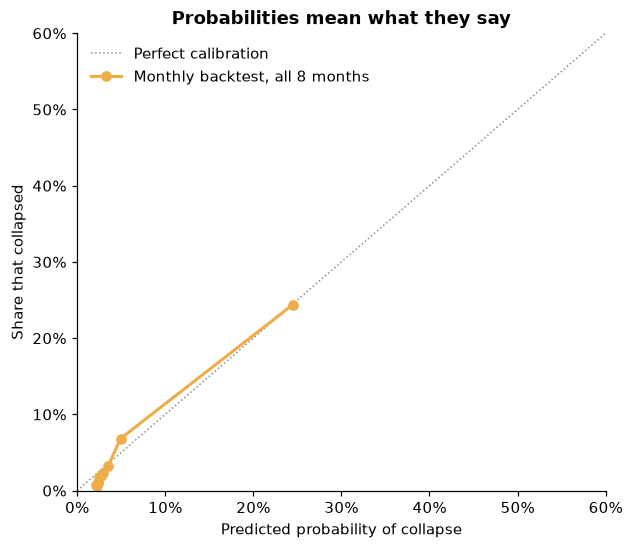

In [11]:
pooled = pd.concat(backtest_frames)
prob_true, prob_pred = calibration_curve(pooled["y"], pooled["p"], n_bins=10, strategy="quantile")
bins = pd.qcut(pooled["p"], 10, duplicates="drop")
calibration_table = pooled.groupby(bins, observed=True).agg(games=("y", "size"), predicted=("p", "mean"), actual=("y", "mean"))
display(calibration_table.round(3))
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.plot([0, 0.6], [0, 0.6], color=COLORS["neutral"], ls=":", lw=1, label="Perfect calibration")
ax.plot(prob_pred, prob_true, marker="o", color=COLORS["accent"], lw=2, label="Monthly backtest, all 8 months")
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set(xlabel="Predicted probability of collapse", ylabel="Share that collapsed", xlim=(0, 0.6), ylim=(0, 0.6),
       title="Probabilities mean what they say")
ax.legend(frameon=False, loc="upper left")
save(fig, "fig05_calibration")
plt.show()

Pooled over the eight test months (12,446 game-months), the riskiest tenth of predictions averaged 24.5% predicted and 24.4% actual. The lower bins are slightly pessimistic (about 2.3% predicted against 0.6–1.0% actual). That errs on the side of caution for games that look safe, and it is small in absolute terms.

## 6. Big games and launch-stage games

,size_band,model,games,collapses,roc_auc,auc_low,auc_high
0,10–100 players,Trend rule,797,40,0.722,0.591,0.834
1,10–100 players,Age rule,797,40,0.632,0.552,0.714
2,10–100 players,Random forest,797,40,0.906,0.852,0.950
3,"100–1,000 players",Trend rule,592,19,0.559,0.398,0.722
4,"100–1,000 players",Age rule,592,19,0.492,0.387,0.602
5,"100–1,000 players",Random forest,592,19,0.726,0.564,0.862
6,"1,000+ players",Trend rule,170,6,0.404,0.018,0.764
7,"1,000+ players",Age rule,170,6,0.488,0.306,0.715
8,"1,000+ players",Random forest,170,6,0.777,0.459,0.989


Saved reports/figures/decline/fig06_by_size.png


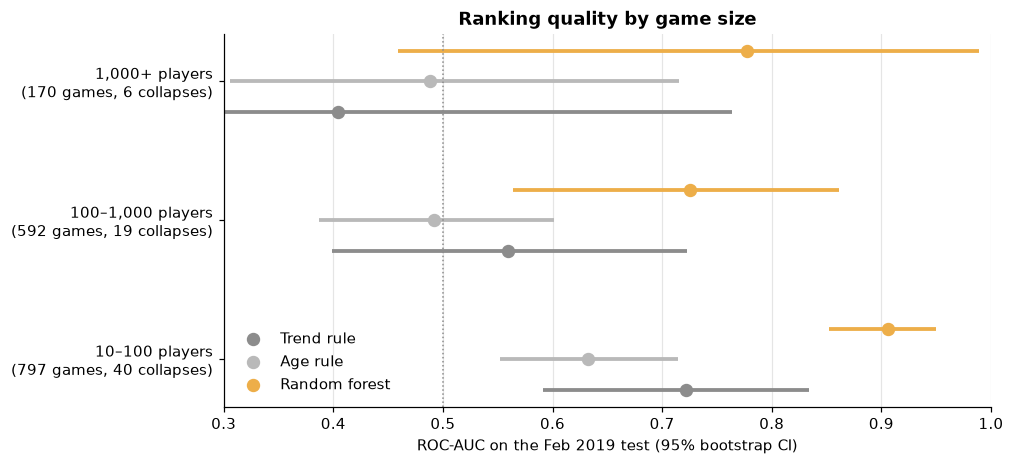

In [12]:
size_rows = []
for band in SIZE_LABELS:
    mask = (test["size_band"] == band).to_numpy()
    for name in ["Trend rule", "Age rule", best_name]:
        scores, y_band = test_scores[name][mask], y_test[mask]
        low, high = bootstrap_ci(y_band, scores, labels_for(name, scores, y_train.mean()), n_boot=500)
        size_rows.append({"size_band": band, "model": name, "games": int(mask.sum()), "collapses": int(y_band.sum()),
                          "roc_auc": roc_auc_score(y_band, scores), "auc_low": low["roc_auc"], "auc_high": high["roc_auc"]})
size_results = pd.DataFrame(size_rows)
display(size_results.round(3))

fig, ax = plt.subplots(figsize=(9, 4.4))
offsets = {"Trend rule": -0.22, "Age rule": 0, best_name: 0.22}
colors = {"Trend rule": COLORS["neutral"], "Age rule": "#b9b9b9", best_name: COLORS["accent"]}
for name, offset in offsets.items():
    part = size_results[size_results["model"] == name].reset_index(drop=True)
    y = np.arange(len(part)) + offset
    ax.hlines(y, part["auc_low"], part["auc_high"], color=colors[name], lw=2.5)
    ax.scatter(part["roc_auc"], y, color=colors[name], s=60, zorder=3, label=name)
part = size_results[size_results["model"] == best_name].reset_index(drop=True)
ax.set_yticks(np.arange(len(part)), [f"{b}\n({g} games, {d} collapses)" for b, g, d in zip(part["size_band"], part["games"], part["collapses"])])
ax.axvline(0.5, color=COLORS["neutral"], ls=":", lw=1)
ax.set_xlim(0.3, 1.0)
ax.grid(axis="x", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
ax.set(xlabel="ROC-AUC on the Feb 2019 test (95% bootstrap CI)", title="Ranking quality by game size")
ax.legend(frameon=False, loc="lower left")
save(fig, "fig06_by_size")
plt.show()

Against the market, few big games collapse: only **6 of 170** games with 1,000+ players did in this test. The model ranks them better than the rules (AUC 0.78 against 0.40 and 0.49), but with six events the interval runs from 0.46 to 0.99, so this is **not evidence either way**. Of the 11 big games on the watch list, 4 collapsed against the market (GRID 2, The Division, H1Z1, Borderlands: The Pre-Sequel). ASTRONEER and Subnautica fell to about half but stayed just above the market line.

**Launch-stage games.** Each game's origin is its own launch: the store release date, or the start of tracking for games released at most 45 days before it. The market change for a launch is the median change of all live games over the same calendar windows. The model is trained on all start dates with these games removed, so nothing about them leaks in.

In [13]:
lag = (static["releasedate"] - DATA_START).dt.days
launch_origin = static["releasedate"].where(lag > 0, DATA_START)
launch_origin = launch_origin[(lag >= -45) & (static["releasedate"] + pd.Timedelta(days=TARGET_END) <= DATA_END)]
launch = build_dataset(launch_origin)
market_by_origin = {o: build_dataset(shared(o))["log_change"].median() for o in launch["origin"].unique()}
launch = add_targets(launch, launch["origin"].map(market_by_origin))
launch["launch_kind"] = np.where(launch["origin"] > DATA_START, "1.0 release during tracking", "Released ≤45 days before tracking")
launch_train = rows[~rows.index.isin(launch.index)]
launch_model = fit_calibrated(best_name, launch_train)
y_launch = launch["collapsed"].to_numpy()
launch_scores = launch_model.predict_proba(launch[ALL_FEATURES])[:, 1]
launch_rows = []
for name, scores in [("Trend rule", -launch["trend_log_per_30d"].fillna(0).to_numpy()), (best_name, launch_scores)]:
    low, high = bootstrap_ci(y_launch, scores, (scores > np.median(scores)).astype(int), n_boot=500)
    launch_rows.append({"model": name, "roc_auc": roc_auc_score(y_launch, scores), "auc_low": low["roc_auc"], "auc_high": high["roc_auc"]})
launch_results = pd.DataFrame(launch_rows).set_index("model")
launch_thirds = pd.qcut(launch_scores, 3, labels=["Lowest third of scores", "Middle third", "Highest third of scores"])
thirds = launch.groupby(launch_thirds, observed=False)["collapsed"].agg(["size", "mean"])
print(f"Launch-stage games: {len(launch)} ({launch['launch_kind'].value_counts().to_dict()}); "
      f"{y_launch.mean():.0%} collapsed relative to the market; mean predicted {launch_scores.mean():.0%}")
display(launch_results.round(3))
display(thirds.round(3))

Launch-stage games: 141 ({'Released ≤45 days before tracking': 74, '1.0 release during tracking': 67}); 35% collapsed relative to the market; mean predicted 11%


,roc_auc,auc_low,auc_high
model,,,
Trend rule,0.751,0.664,0.835
Random forest,0.769,0.680,0.859


,size,mean
Lowest third of scores,47,0.128
Middle third,47,0.255
Highest third of scores,47,0.681


**Launch stage.** 35% of the 141 launches collapsed against the market. The model's riskiest third collapsed 68% of the time and its safest third 13%. On ranking it is only slightly ahead of the trend rule (AUC 0.769 vs 0.751, intervals overlapping), so the earlier conclusion stands: the product is for live catalogues, and launches need launch-specific data.

## 7. Does Twitch help? Ablation and importance

In [14]:
ABLATION_SETS = {
    "Metadata only": META_FEATURES, "Twitch only": TWITCH_FEATURES, "Metadata + Twitch": META_FEATURES + TWITCH_FEATURES,
    "Steam only": STEAM_FEATURES, "Metadata + Steam": META_FEATURES + STEAM_FEATURES, "Metadata + Steam + Twitch": ALL_FEATURES,
}
ablation_rows, ablation_scores = [], {}
for set_name, columns in ABLATION_SETS.items():
    scores = make_model(best_name).fit(train[columns], y_train).predict_proba(test[columns])[:, 1]
    ablation_scores[set_name] = scores
    low, high = bootstrap_ci(y_test, scores, (scores >= 0.5).astype(int), n_boot=500)
    ablation_rows.append({"feature_set": set_name, "n_features": len(columns), "test_auc": roc_auc_score(y_test, scores),
                          "test_auc_low": low["roc_auc"], "test_auc_high": high["roc_auc"],
                          "watchlist_recall": top_share(y_test, scores)[1]})
ablation = pd.DataFrame(ablation_rows).set_index("feature_set")
display(ablation.round(3))
rng = np.random.default_rng(RANDOM_STATE)
with_twitch, without_twitch = ablation_scores["Metadata + Steam + Twitch"], ablation_scores["Metadata + Steam"]
deltas = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].min() != y_test[idx].max():
        deltas.append(roc_auc_score(y_test[idx], with_twitch[idx]) - roc_auc_score(y_test[idx], without_twitch[idx]))
twitch_delta = (roc_auc_score(y_test, with_twitch) - roc_auc_score(y_test, without_twitch), *np.quantile(deltas, [0.025, 0.975]))
print(f"AUC change from adding Twitch: {twitch_delta[0]:+.4f} (95% CI {twitch_delta[1]:+.4f} to {twitch_delta[2]:+.4f})")

,n_features,test_auc,test_auc_low,test_auc_high,watchlist_recall
feature_set,,,,,
Metadata only,42,0.630,0.561,0.700,0.246
Twitch only,7,0.604,0.536,0.689,0.262
Metadata + Twitch,49,0.652,0.581,0.724,0.292
Steam only,8,0.817,0.755,0.868,0.585
Metadata + Steam,50,0.850,0.788,0.906,0.662
Metadata + Steam + Twitch,57,0.843,0.772,0.901,0.646


AUC change from adding Twitch: -0.0063 (95% CI -0.0223 to +0.0087)


,auc_drop,std
group,,
Metadata,0.0511,0.0169
Steam activity,0.2486,0.0207
Twitch,0.0066,0.0069
Genres + tags,0.0169,0.0102


,auc_drop,std
feature,,
volatility,0.0189,0.0072
trend_log_per_30d,0.0148,0.0085
last_vs_first_month,0.0117,0.0080
log_early_min,0.0080,0.0097
log_early_mean,0.0067,0.0027
log_twitch_peak_viewers,0.0056,0.0033
freetoplay,0.0055,0.0074
tag_free_to_play,0.0035,0.0045
tag_great_soundtrack,0.0034,0.0011


Saved reports/figures/decline/fig07_ablation_importance.png


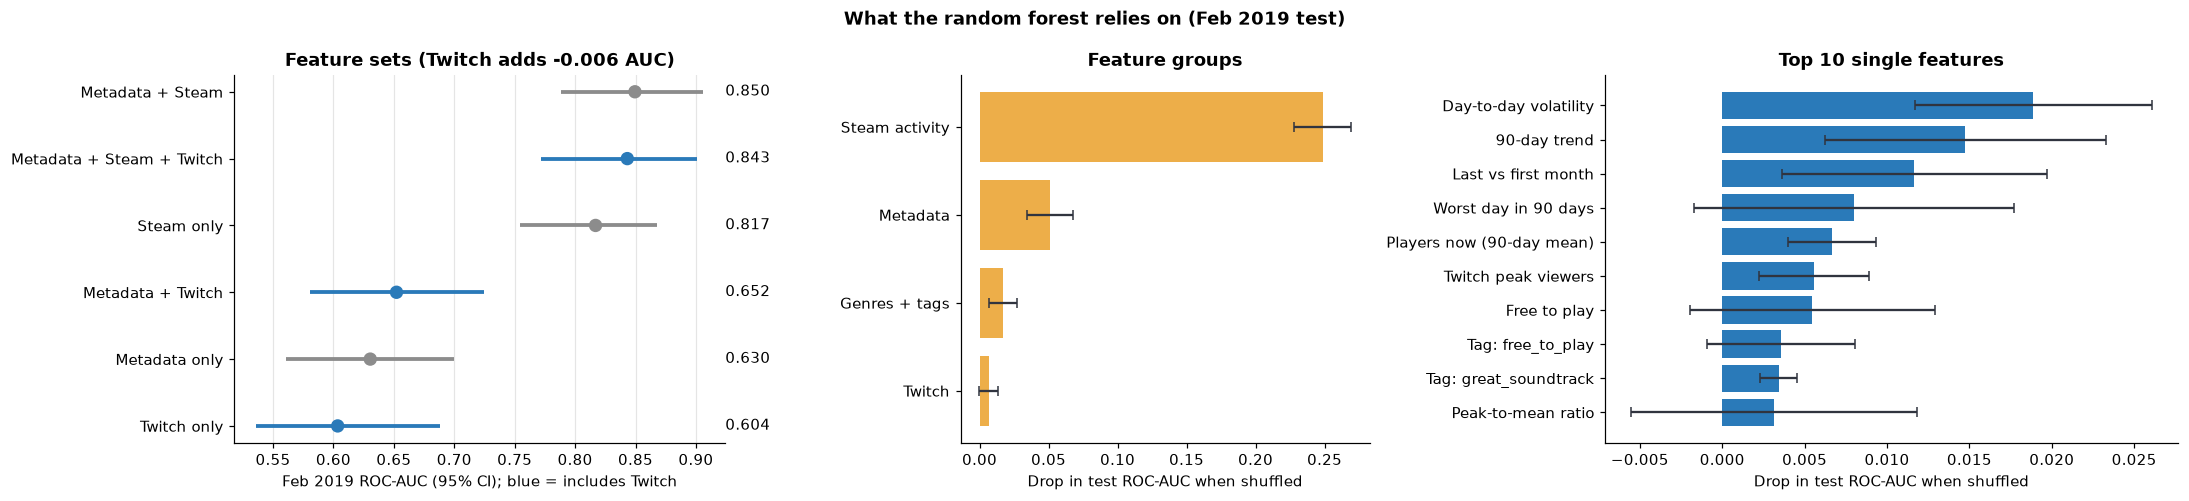

In [15]:
def permutation_auc_drop(model, frame, y, columns_to_shuffle, n_repeats=20, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(frame[ALL_FEATURES])[:, 1])
    drops = []
    for _ in range(n_repeats):
        shuffled = frame[ALL_FEATURES].copy()
        shuffled[columns_to_shuffle] = shuffled[columns_to_shuffle].to_numpy()[rng.permutation(len(frame))]
        drops.append(base - roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
    return np.mean(drops), np.std(drops)


group_importance = pd.DataFrame([(g, *permutation_auc_drop(best_model, test, y_test, cols)) for g, cols in
                                 {**FEATURE_GROUPS, "Genres + tags": GENRE_COLUMNS + TAG_COLUMNS}.items()],
                                columns=["group", "auc_drop", "std"]).set_index("group")
single_importance = pd.DataFrame([(f, *permutation_auc_drop(best_model, test, y_test, [f], n_repeats=10)) for f in ALL_FEATURES],
                                 columns=["feature", "auc_drop", "std"]).set_index("feature").sort_values("auc_drop", ascending=False)
display(group_importance.round(4))
display(single_importance.head(12).round(4))

FEATURE_LABELS = {
    "log_early_mean": "Players now (90-day mean)", "log_early_min": "Worst day in 90 days", "low_day_share": "Share of near-empty days",
    "trend_log_per_30d": "90-day trend", "last_vs_first_month": "Last vs first month", "volatility": "Day-to-day volatility",
    "log_peak_to_mean": "Peak-to-mean ratio", "weekend_uplift": "Weekend uplift", "age_years": "Game age",
    "log_twitch_avg_viewers": "Twitch avg viewers", "log_twitch_view_minutes": "Twitch watch time",
    "twitch_viewers_per_player": "Twitch viewers per player", "log_twitch_peak_viewers": "Twitch peak viewers",
    "n_languages": "Supported languages", "n_packages": "Store packages", "log_publisher_catalog": "Publisher catalogue size",
    "n_tags": "Number of tags", "freetoplay": "Free to play", "log_twitch_avg_channels": "Twitch channels",
    "twitch_mapped": "Has a Twitch category", "twitch_months_in_top": "Months in Twitch top 2,000", "early_access": "Still in Early Access",
    "n_developers": "Number of developers", "release_unknown": "Release date unknown",
}
fig, axes = plt.subplots(1, 3, figsize=(20, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1.4]})
order = ablation.sort_values("test_auc").index
y = np.arange(len(order))
colors = [COLORS["stable"] if "Twitch" in n else COLORS["neutral"] for n in order]
axes[0].hlines(y, ablation.loc[order, "test_auc_low"], ablation.loc[order, "test_auc_high"], color=colors, lw=2.5)
axes[0].scatter(ablation.loc[order, "test_auc"], y, color=colors, s=60, zorder=3)
for yi, value in zip(y, ablation.loc[order, "test_auc"]):
    axes[0].text(1.0, yi, f"{value:.3f}", transform=axes[0].get_yaxis_transform(), va="center", fontsize=9.5)
axes[0].set_yticks(y, order)
axes[0].set(xlabel="Feb 2019 ROC-AUC (95% CI); blue = includes Twitch", title=f"Feature sets (Twitch adds {twitch_delta[0]:+.3f} AUC)")
axes[0].grid(axis="x", color="#e5e5e5", lw=0.8)
g = group_importance.sort_values("auc_drop")
axes[1].barh(g.index, g["auc_drop"], xerr=g["std"], color=COLORS["accent"], ecolor=COLORS["dark"], capsize=3)
axes[1].set(xlabel="Drop in test ROC-AUC when shuffled", title="Feature groups")
s = single_importance.head(10).iloc[::-1]
axes[2].barh([FEATURE_LABELS.get(f, f.replace("genre_", "Genre: ").replace("tag_", "Tag: ")) for f in s.index], s["auc_drop"],
             xerr=s["std"], color=COLORS["stable"], ecolor=COLORS["dark"], capsize=3)
axes[2].set(xlabel="Drop in test ROC-AUC when shuffled", title="Top 10 single features")
fig.suptitle(f"What the {best_name.lower()} relies on (Feb 2019 test)", fontweight="bold")
fig.tight_layout()
save(fig, "fig07_ablation_importance")
plt.show()

**Twitch still adds nothing** (−0.006 AUC, 95% CI −0.022 to +0.009).

- Steam activity remains the core: shuffling it costs 0.25 AUC.
- Metadata now helps a little: Steam-only 0.817, Metadata + Steam 0.850.
- The strongest single signals are **volatility**, the **trend**, the **last-vs-first month** change and the **worst day**.

## 8. Robustness

### 8a. How big a collapse?

In [16]:
sensitivity_rows = []
for ratio, label in [(0.75, "lost ≥ 25% vs market"), (0.5, "lost ≥ 50% vs market"), (0.25, "lost ≥ 75% vs market")]:
    y_fit = train["relative_log_change"].lt(np.log(ratio)).astype(int)
    y_eval = test["relative_log_change"].lt(np.log(ratio)).astype(int).to_numpy()
    scores = make_model(best_name).fit(train[ALL_FEATURES], y_fit).predict_proba(test[ALL_FEATURES])[:, 1]
    sensitivity_rows.append({"definition": label, "test_rate": y_eval.mean(), "test_events": int(y_eval.sum()),
                             "trend_rule_auc": roc_auc_score(y_eval, test_scores["Trend rule"]), "model_auc": roc_auc_score(y_eval, scores),
                             "model_watchlist_recall": top_share(y_eval, scores)[1]})
sensitivity = pd.DataFrame(sensitivity_rows).set_index("definition")
display(sensitivity.round(3))

,test_rate,test_events,trend_rule_auc,model_auc,model_watchlist_recall
definition,,,,,
lost ≥ 25% vs market,0.153,239,0.511,0.808,0.377
lost ≥ 50% vs market,0.042,65,0.645,0.843,0.646
lost ≥ 75% vs market,0.013,20,0.764,0.956,0.850


### 8b. How large will the change be? (regression)

In [17]:
regressor = Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", RandomForestRegressor(
    n_estimators=500, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))])
regressor.fit(train[ALL_FEATURES], train["relative_log_change"])
truth = test["relative_log_change"].to_numpy()
predictions = {"No change vs market": np.zeros(len(test)),
               "Trend extrapolation": test["trend_log_per_30d"].fillna(0).to_numpy() * HORIZON_MONTHS,
               "Random forest": regressor.predict(test[ALL_FEATURES])}
regression_results = pd.DataFrame([{
    "model": name, "MAE_log": np.mean(np.abs(pred - truth)),
    "rank_corr_with_actual_change": pd.Series(pred).corr(pd.Series(truth), method="spearman") if pred.std() > 0 else np.nan,
} for name, pred in predictions.items()]).set_index("model")
display(regression_results.round(3))

,MAE_log,rank_corr_with_actual_change
model,,
No change vs market,0.269,NaN
Trend extrapolation,0.919,0.014
Random forest,0.250,0.380


- **Threshold:** for every collapse definition (25%, 50% or 75% below the market), the model ranks far better than the trend rule.
- **Size of the change:** the forest now predicts the size of the relative change slightly better than "no change" (MAE 0.250 vs 0.269 in log units; rank correlation 0.38). That is useful as a hint, but too weak to sell as an audience forecast.

## 9. Explaining each flag

A random forest's probability can be split exactly into one contribution per feature. Each tree's prediction is the training average plus the change at every split along the path a game takes, and each change belongs to the feature used at that split (the "tree interpreter" decomposition). Averaged over the 500 trees, the contributions plus the average add up to the forest's score. The sigmoid calibration on top is monotonic, so the ranking is unchanged.

Contributions are grouped into themes a publisher recognises: level, floor, near-empty days, spikiness, trend, last-vs-first month, peak, weekend pattern, age, genre and tags, business model, store page, publisher size, Twitch. The three themes that push a game's risk up most become its reasons, each written with the game's own numbers.

In [18]:
from scipy import sparse


def tree_contributions(pipeline, frame):
    """Per-row, per-feature contributions to a fitted random forest's probability of class 1."""
    imputed = pipeline.named_steps["impute"].transform(frame[ALL_FEATURES])
    forest = pipeline.named_steps["model"]
    positive = list(forest.classes_).index(1)
    total = np.zeros((len(frame), len(ALL_FEATURES)))
    bias = 0.0
    for tree in forest.estimators_:
        t = tree.tree_
        value = t.value[:, 0, :]
        value = value[:, positive] / value.sum(axis=1)
        nodes = np.arange(t.node_count)
        parent = np.full(t.node_count, -1)
        inner = t.children_left >= 0
        parent[t.children_left[inner]] = nodes[inner]
        parent[t.children_right[inner]] = nodes[inner]
        child = parent >= 0
        delta = sparse.csr_matrix((value[child] - value[parent[child]], (nodes[child], t.feature[parent[child]])),
                                  shape=(t.node_count, len(ALL_FEATURES)))
        total += (tree.decision_path(imputed.astype(np.float32)) @ delta).toarray()
        bias += value[0]
    n_trees = len(forest.estimators_)
    return pd.DataFrame(total / n_trees, index=frame.index, columns=ALL_FEATURES), bias / n_trees


THEMES = {
    "level": ["log_early_mean"], "floor": ["log_early_min"], "empty_days": ["low_day_share"], "spiky": ["volatility"],
    "trend": ["trend_log_per_30d"], "last_month": ["last_vs_first_month"], "peak": ["log_peak_to_mean"],
    "weekend": ["weekend_uplift"], "age": ["age_years", "early_access", "release_unknown"],
    "genre_tags": GENRE_COLUMNS + TAG_COLUMNS, "business": ["freetoplay", "freetoplay_unknown"],
    "store_page": ["n_tags", "n_languages", "n_packages", "n_developers"], "publisher": ["log_publisher_catalog"],
    "twitch": TWITCH_FEATURES,
}


def pretty(column):
    words = column.replace("genre_", "").replace("tag_", "").replace("_", " ").title()
    return words.replace("Rpg", "RPG").replace("Fps", "FPS").replace("Pvp", "PvP").replace("Co Op", "Co-op")


def reason_text(theme, row, contrib_row, reference):
    pct = lambda col: (reference[col] < row[col]).mean()
    if theme == "level":
        return f"Small player base: {row['early_mean']:,.0f} average players"
    if theme == "floor":
        worst = np.expm1(row["log_early_min"])
        return f"Weak floor: worst day {worst:,.0f} players, {worst / max(row['early_mean'], 1e-9):.0%} of the average"
    if theme == "empty_days":
        return f"{row['low_day_share']:.0%} of days nearly empty"
    if theme == "spiky":
        return f"Spiky player counts: more volatile than {min(pct('volatility'), 0.99):.0%} of live games"
    if theme == "trend":
        t = row["trend_log_per_30d"]
        return (f"Falling about {1 - np.exp(t):.0%} a month" if t < 0
                else f"Rising {np.exp(t) - 1:.0%} a month; spikes like this usually fade")
    if theme == "last_month":
        d = row["last_vs_first_month"]
        return (f"Last month {1 - np.exp(d):.0%} below the first" if d < 0
                else f"Last month {np.exp(d) - 1:.0%} above the first; recent bumps usually fade")
    if theme == "peak":
        return f"Busiest day {np.exp(row['log_peak_to_mean']):.1f}× the average: a one-off spike"
    if theme == "weekend":
        return f"Weekend players {np.exp(row['weekend_uplift']) - 1:+.0%} vs weekdays"
    if theme == "age":
        if row["early_access"] == 1:
            return "Still in Early Access"
        if row["release_unknown"] == 1:
            return "No release date on the store page"
        return (f"Young game: {row['age_years'] * 12:.0f} months since release" if row["age_years"] < 1
                else f"{row['age_years']:.1f} years since release")
    if theme == "genre_tags":
        active = [c for c in GENRE_COLUMNS + TAG_COLUMNS if row[c] == 1 and contrib_row[c] > 0]
        active = sorted(active, key=lambda c: -contrib_row[c])[:3]
        return "Genre and tags: " + ", ".join(pretty(c) for c in active) if active else "Genre and tag mix"
    if theme == "business":
        return "Free to play" if row["freetoplay"] == 1 else "Paid game"
    if theme == "store_page":
        return f"Store page: {row['n_languages']:.0f} languages, {row['n_tags']:.0f} tags"
    if theme == "publisher":
        size = np.expm1(row["log_publisher_catalog"])
        return "Single-game publisher" if size < 1.5 else f"Publisher has {size:.0f} games in the dataset"
    if theme == "twitch":
        viewers = np.expm1(row["log_twitch_avg_viewers"])
        return "No Twitch audience" if viewers < 1 else f"Twitch audience: {viewers:,.0f} average viewers"
    return theme


def explain(pipeline, frame, n_reasons=3):
    contributions, bias = tree_contributions(pipeline, frame)
    themed = pd.DataFrame({theme: contributions[cols].sum(axis=1) for theme, cols in THEMES.items()})
    reasons = []
    for appid, theme_row in themed.iterrows():
        top = theme_row[theme_row > 0].sort_values(ascending=False).head(n_reasons)
        reasons.append([reason_text(theme, frame.loc[appid], contributions.loc[appid], frame) for theme in top.index])
    return pd.Series(reasons, index=frame.index), themed, bias


base_forest = best_model.calibrated_classifiers_[0].estimator
contributions, bias = tree_contributions(base_forest, test)
raw = base_forest.predict_proba(test[ALL_FEATURES])[:, 1]
print(f"Decomposition check: max |bias + contributions − forest score| = {np.abs(bias + contributions.sum(axis=1) - raw).max():.2e}")
test_reasons, test_themes, _ = explain(base_forest, test)
theme_share = (test_themes.clip(lower=0).div(test_themes.clip(lower=0).sum(axis=1), axis=0)
               .loc[test_scores[best_name] >= np.quantile(test_scores[best_name], 1 - WATCHLIST_SHARE)].mean().sort_values(ascending=False))
display(theme_share.round(3).rename("share of risk-raising contribution, watch-list games"))

Decomposition check: max |bias + contributions − forest score| = 7.77e-16


spiky         0.216
peak          0.144
floor         0.139
trend         0.083
genre_tags    0.081
last_month    0.078
business      0.074
store_page    0.040
weekend       0.037
twitch        0.031
empty_days    0.028
level         0.026
age           0.013
publisher     0.010
Name: share of risk-raising contribution, watch-list games, dtype: float64

The decomposition is exact: contributions plus the average equal the forest's score to machine precision.

Across watch-list games, risk comes mostly from **spiky player counts** (22% of the risk-raising contribution), **one-off peaks** (14%), a **weak floor** (14%) and the **trend** (8%). Many of the riskiest games are small titles whose 90-day average was inflated by a single burst of players, such as a giveaway or free weekend, followed by near-empty days. The model has learned that such bursts do not last.

## 10. Deliverable: watch lists with probabilities and reasons

Tiers are set by rank, so a team always has the same size of review list:

- **Watch list**: the riskiest 10%;
- **Monitor**: the next 20%;
- **Stable**: the remaining 70%.

Each game also shows its calibrated probability and its three reasons.

### 10a. Backtest (Feb 2019 start)

,games,collapsed,share_collapsed,mean_probability,median_players_now,share_of_all_collapses
tier,,,,,,
Watch list,155,42,0.271,0.215,55.029,0.646
Monitor,312,10,0.032,0.040,74.332,0.154
Stable,1092,13,0.012,0.024,114.956,0.200


Saved reports/figures/decline/fig08_tiers_backtest.png


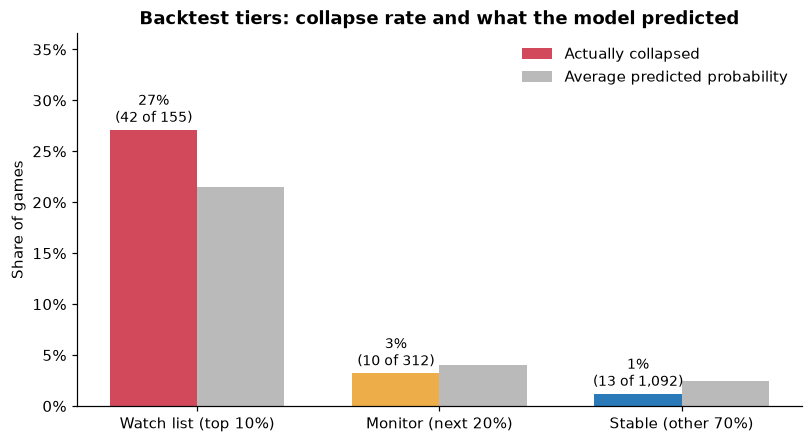

,name,early_mean,relative_change,probability,reasons
appid,,,,,
585790,Fergus The Fly,23.231924,1.361171,0.896472,[Spiky player counts: more volatile than 99% o...
551670,TWIN BROS,15.933458,0.066135,0.890450,"[Weak floor: worst day 0 players, 0% of the av..."
574620,Word Killer: Zorgilonian Chronicles,30.260129,0.036748,0.873381,[Spiky player counts: more volatile than 99% o...
391660,Incitement 3,19.153092,0.392750,0.849947,"[Weak floor: worst day 0 players, 1% of the av..."
453980,Airstrike HD,33.002237,0.037179,0.838197,"[Weak floor: worst day 0 players, 0% of the av..."
385070,Atonement: Scourge of Time,16.366770,0.254799,0.832794,[Spiky player counts: more volatile than 99% o...
444480,Broken Dreams,12.527028,0.956350,0.816545,[Spiky player counts: more volatile than 98% o...
448440,Bizarre Earthquake,18.096683,0.142749,0.812545,"[Weak floor: worst day 0 players, 0% of the av..."
449680,SAMOLIOTIK,21.133891,0.347841,0.759284,[Spiky player counts: more volatile than 99% o...


In [19]:
TIER_LABELS = ["Watch list", "Monitor", "Stable"]


def assign_tiers(scores):
    rank = pd.Series(scores).rank(ascending=False, method="first") / len(scores)
    return pd.cut(rank, [0, 0.1, 0.3, 1.0], labels=TIER_LABELS).to_numpy()


backtest_table = test[["name", "publisher", "early_mean", "future_mean", "change_ratio", "market_log_change", "collapsed", "size_band"]].copy()
backtest_table["relative_change"] = np.exp(test["relative_log_change"])
backtest_table["probability"] = test_scores[best_name]
backtest_table["tier"] = pd.Categorical(assign_tiers(backtest_table["probability"].to_numpy()), categories=TIER_LABELS)
backtest_table["reasons"] = test_reasons
tier_summary = backtest_table.groupby("tier", observed=False).agg(
    games=("name", "size"), collapsed=("collapsed", "sum"), share_collapsed=("collapsed", "mean"),
    mean_probability=("probability", "mean"), median_players_now=("early_mean", "median"))
tier_summary["share_of_all_collapses"] = tier_summary["collapsed"] / backtest_table["collapsed"].sum()
display(tier_summary.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
xs = np.arange(len(tier_summary))
ax.bar(xs - 0.18, tier_summary["share_collapsed"], width=0.36, color=[COLORS["decline"], COLORS["accent"], COLORS["stable"]], label="Actually collapsed")
ax.bar(xs + 0.18, tier_summary["mean_probability"], width=0.36, color=COLORS["neutral"], alpha=0.6, label="Average predicted probability")
for xi, (share, lost, games) in enumerate(zip(tier_summary["share_collapsed"], tier_summary["collapsed"], tier_summary["games"])):
    ax.text(xi - 0.18, share + 0.008, f"{share:.0%}\n({lost} of {games:,})", ha="center", fontsize=9)
ax.set_xticks(xs, [f"{t} ({s})" for t, s in zip(TIER_LABELS, ["top 10%", "next 20%", "other 70%"])])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, max(tier_summary["share_collapsed"].max(), tier_summary["mean_probability"].max()) * 1.35)
ax.set(ylabel="Share of games", title="Backtest tiers: collapse rate and what the model predicted")
ax.legend(frameon=False, loc="upper right")
save(fig, "fig08_tiers_backtest")
plt.show()
display(backtest_table.sort_values("probability", ascending=False).head(10)[["name", "early_mean", "relative_change", "probability", "reasons"]])

| Tier | Share collapsed | Average predicted | Share of all collapses |
|---|---:|---:|---:|
| Watch list (155 games) | 27% | 22% | 65% |
| Monitor (312 games) | 3.2% | 4.0% | 15% |
| Stable (1,092 games) | 1.2% | 2.4% | 20% |

Each tier's predicted probability matches its real collapse rate closely, so a publisher can read the probabilities at face value.

Big games (1,000+ players): 170, 6 collapsed; 11 on the watch list, 4 of them collapsed


,name,early_mean,change_ratio,relative_change,probability,reasons
appid,,,,,,
361420,ASTRONEER,3898.03,0.48,0.50,0.58,"[Last month 72% below the first, Falling about..."
264710,Subnautica,4003.69,0.56,0.59,0.40,"[Falling about 42% a month, Last month 65% bel..."
44350,GRID 2,1224.49,0.23,0.24,0.29,[Spiky player counts: more volatile than 99% o...
365590,Tom Clancy's The Division,4097.99,0.16,0.17,0.16,"[Falling about 50% a month, Last month 77% bel..."
433850,H1Z1,2384.35,0.30,0.32,0.15,[Spiky player counts: more volatile than 95% o...
311690,Enter the Gungeon,3027.80,0.49,0.52,0.11,[Spiky player counts: more volatile than 96% o...
49520,Borderlands 2,14690.07,0.49,0.51,0.11,[Spiky player counts: more volatile than 93% o...
489520,Minion Masters,1000.08,1.47,1.55,0.11,[Spiky player counts: more volatile than 92% o...
578080,PLAYERUNKNOWN'S BATTLEGROUNDS,419438.78,0.73,0.77,0.09,"[Genre and tags: FPS, Massively Multiplayer, S..."


Saved reports/figures/decline/fig09_examples.png


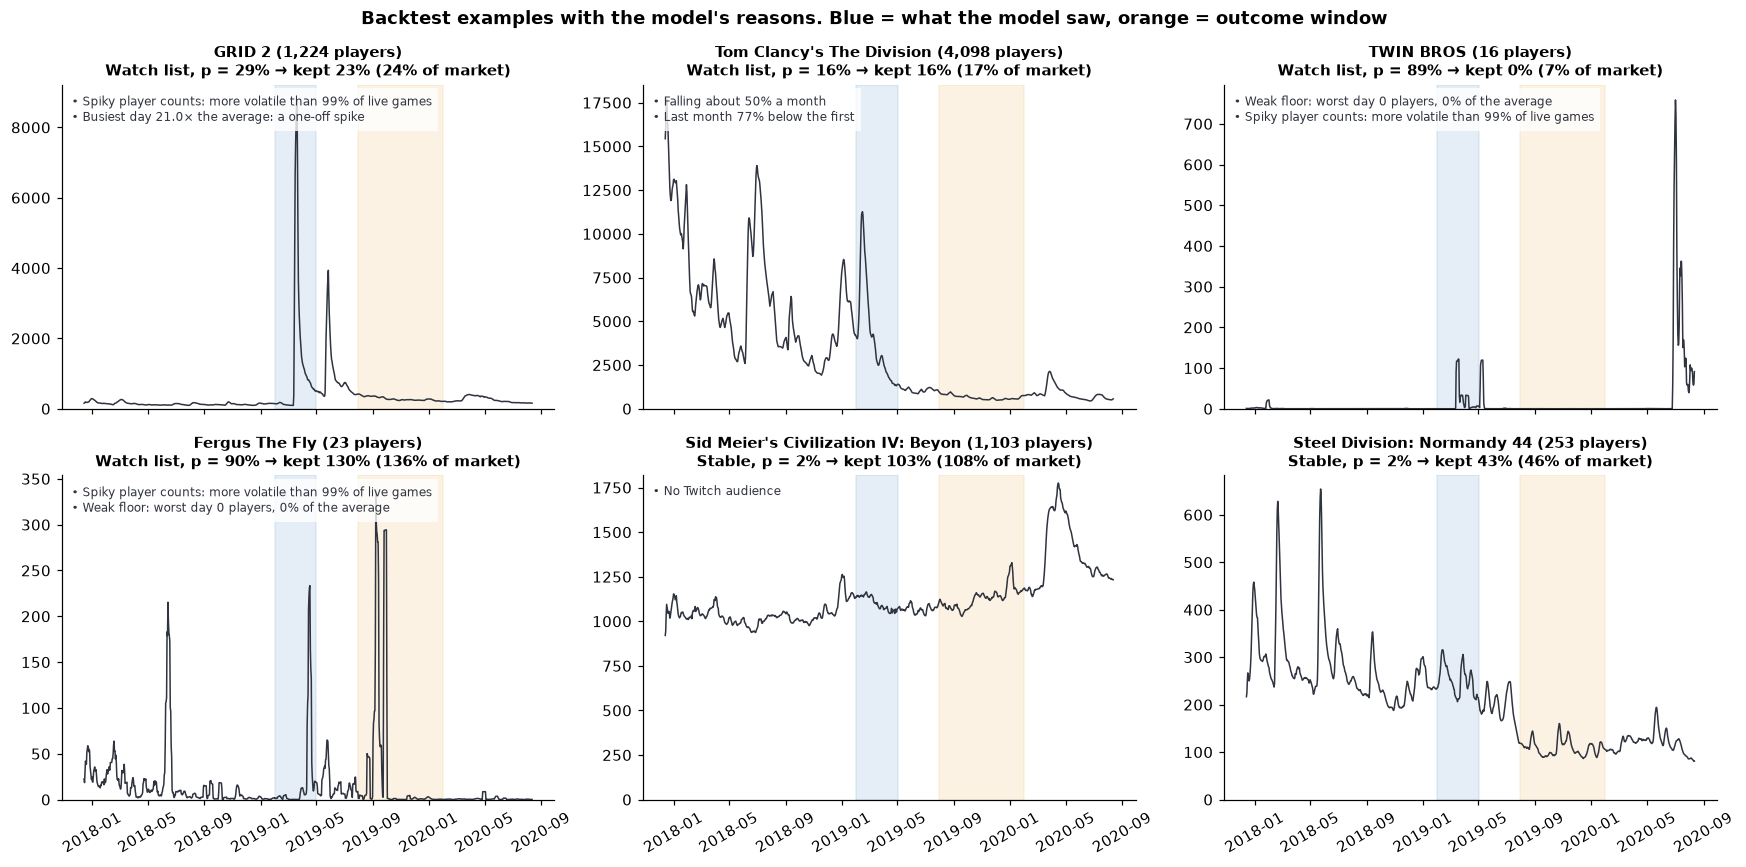

In [20]:
big = backtest_table[backtest_table["early_mean"] >= 1000]
big_flagged = big[big["tier"] == "Watch list"].sort_values("probability", ascending=False)
print(f"Big games (1,000+ players): {len(big)}, {big['collapsed'].sum()} collapsed; {len(big_flagged)} on the watch list, "
      f"{big_flagged['collapsed'].sum()} of them collapsed")
display(big_flagged[["name", "early_mean", "change_ratio", "relative_change", "probability", "reasons"]].round(2))

examples = pd.concat([
    big[(big["tier"] == "Watch list") & (big["collapsed"] == 1)].nlargest(2, "probability"),
    backtest_table[(backtest_table["tier"] == "Watch list") & (backtest_table["collapsed"] == 1) & (backtest_table["early_mean"] < 1000)].nlargest(1, "probability"),
    backtest_table[(backtest_table["tier"] == "Watch list") & (backtest_table["collapsed"] == 0)].nlargest(1, "probability"),
    big[(big["tier"] == "Stable") & (big["collapsed"] == 0)].nsmallest(1, "probability"),
    backtest_table[(backtest_table["tier"] == "Stable") & (backtest_table["collapsed"] == 1)].nsmallest(1, "probability"),
])
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for ax, (appid, row) in zip(axes.ravel(), examples.iterrows()):
    history = panel[panel["appid"] == appid].set_index("date")["mean_player_count"].rolling(7, min_periods=1).mean()
    ax.plot(history.index, history, color=COLORS["dark"], lw=1)
    ax.axvspan(HEADLINE_TEST, HEADLINE_TEST + pd.Timedelta(days=FEATURE_DAYS), color=COLORS["stable"], alpha=0.12)
    ax.axvspan(HEADLINE_TEST + pd.Timedelta(days=TARGET_START), HEADLINE_TEST + pd.Timedelta(days=TARGET_END), color=COLORS["accent"], alpha=0.15)
    ax.set_title(f"{row['name'][:34]} ({row['early_mean']:,.0f} players)\n{row['tier']}, p = {row['probability']:.0%} → "
                 f"kept {row['change_ratio']:.0%} ({row['relative_change']:.0%} of market)", fontsize=10)
    ax.text(0.02, 0.97, "\n".join("• " + r for r in row["reasons"][:2]), transform=ax.transAxes, va="top", fontsize=8,
            color=COLORS["dark"], bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", labelrotation=30)
fig.suptitle("Backtest examples with the model's reasons. Blue = what the model saw, orange = outcome window", fontweight="bold")
fig.tight_layout()
save(fig, "fig09_examples")
plt.show()

### 10b. Forward watch list from the last 90 days of data

The deployable model is trained on **all 21 start dates** (Dec 2017 – Aug 2019) and scores every live game on 15 May – 12 Aug 2020. The outcome window, Nov 2020 – Aug 2021, lies beyond the data, so this is a forecast. Because the target is relative to the market, the lockdown boom in the scoring window matters less than it would for the old target.

In [21]:
forecast_origin = DATA_END - pd.Timedelta(days=FEATURE_DAYS - 1)
latest = build_dataset(shared(forecast_origin), labelled=False)
final_model = fit_calibrated(best_name, rows)
forecast = latest[["name", "publisher", "early_mean", "trend_log_per_30d"]].rename(
    columns={"early_mean": "mean_players_last_90_days", "trend_log_per_30d": "trend_log_per_30_days"})
forecast["probability"] = final_model.predict_proba(latest[ALL_FEATURES])[:, 1]
forecast["tier"] = assign_tiers(forecast["probability"].to_numpy())
forecast["reasons"], _, _ = explain(final_model.calibrated_classifiers_[0].estimator, latest)
forecast = forecast.sort_values("probability", ascending=False)
print(f"Forecast start {forecast_origin.date()}: {len(forecast):,} live games; average probability {forecast['probability'].mean():.1%}")
display(forecast.head(10))


def export(frame, path_stem, outcome):
    out = frame.copy()
    out["reasons"] = out["reasons"].map(lambda r: " | ".join(r))
    out.round(4).to_csv(REPORT_DIR / f"{path_stem}.csv", index_label="appid")
    records = []
    for rank, (appid, row) in enumerate(frame.iterrows(), start=1):
        record = {"rank": rank, "appid": int(appid), "name": row["name"], "publisher": row["publisher"] if isinstance(row["publisher"], str) else "",
                  "players": round(float(row["early_mean" if outcome else "mean_players_last_90_days"]), 1),
                  "p": round(float(row["probability"]), 4), "tier": str(row["tier"]), "reasons": list(row["reasons"])}
        if outcome:
            record.update({"kept": round(float(row["change_ratio"]), 3), "vs_market": round(float(row["relative_change"]), 3),
                           "collapsed": int(row["collapsed"])})
        records.append(record)
    (REPORT_DIR / f"{path_stem}.json").write_text(json.dumps(records, ensure_ascii=False), encoding="utf-8")
    print(f"Wrote reports/{path_stem}.csv and .json ({len(records):,} games)")


export(backtest_table.sort_values("probability", ascending=False), "decline_watchlist_backtest_2019", outcome=True)
export(forecast, "decline_watchlist_forecast_2020-08", outcome=False)

Forecast start 2020-05-15: 1,554 live games; average probability 5.1%


,name,publisher,mean_players_last_90_days,trend_log_per_30_days,probability,tier,reasons
appid,,,,,,,
601340,Project of the Developer,AL-GAME,116.523421,1.870258,0.872799,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."
621880,Phoenix Dynasty 2,Ntroy LTD,14.934379,-1.272343,0.852073,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."
631530,Fight or Die 2,Vyacheslav Shilikhin,30.735890,-1.517194,0.839114,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."
619520,Destruction 48,Vyacheslav Shilikhin,27.793826,-1.444602,0.833021,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."
616360,Crimson Earth,EHTechnology,27.483185,-1.419859,0.828531,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."
528510,Turbo Pug 3D,Back To Basics Gaming,32.774280,-0.454638,0.816682,Watch list,"[Weak floor: worst day 0 players, 1% of the av..."
515470,Hyper color ball,Back To Basics Gaming,22.269833,-0.421085,0.797144,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."
551670,TWIN BROS,NedoStudio,122.438143,1.982649,0.780205,Watch list,[Busiest day 39.6× the average: a one-off spik...
567250,Cat Goes Platform,!Lim studio,10.292173,-0.888846,0.779229,Watch list,"[Weak floor: worst day 0 players, 0% of the av..."


Wrote reports/decline_watchlist_backtest_2019.csv and .json (1,559 games)
Wrote reports/decline_watchlist_forecast_2020-08.csv and .json (1,554 games)


## 11. Save metrics

In [22]:
def frame_dict(frame):
    return json.loads(frame.round(4).to_json(orient="index", default_handler=str))


catch_curve = {}
for name in ["Trend rule", best_name]:
    order = np.argsort(-test_scores[name], kind="stable")
    cumulative = np.cumsum(y_test[order])
    catch_curve[name] = [0.0] + [round(float(cumulative[max(1, int(np.ceil(k / 100 * len(y_test)))) - 1] / y_test.sum()), 4)
                                 for k in range(1, 101)]

results = {
    "settings": {"feature_days": FEATURE_DAYS, "target_days": [TARGET_START, TARGET_END], "min_players": MIN_PLAYERS,
                 "decline_ratio_vs_market": DECLINE_RATIO, "watchlist_share": WATCHLIST_SHARE, "headline_test": str(HEADLINE_TEST.date()),
                 "training_starts_headline": int(train["origin"].nunique()), "training_rows_headline": len(train),
                 "best_model": best_name},
    "starts": json.loads(starts.rename(index=lambda d: str(d.date())).round(4).to_json(orient="index")),
    "groups": {k: v.round(4).to_dict(orient="records") for k, v in groups.items()},
    "cv": {m: round(cv_results.loc[m, ("roc_auc", "mean")], 4) for m in cv_results.index},
    "test": frame_dict(test_results),
    "monthly_backtest": json.loads(backtest.rename(index=str).round(4).to_json(orient="index")),
    "monthly_summary": json.loads(backtest[summary_cols].agg(["mean", "min", "max"]).round(4).to_json()),
    "calibration_bins": json.loads(calibration_table.reset_index(drop=True).round(4).to_json(orient="records")),
    "by_size": size_results.round(4).to_dict(orient="records"),
    "launch": {"games": len(launch), "collapses": int(y_launch.sum()), "results": frame_dict(launch_results),
               "thirds": json.loads(thirds.round(4).to_json(orient="index"))},
    "ablation": frame_dict(ablation),
    "twitch_auc_change": [round(v, 4) for v in twitch_delta],
    "group_importance": frame_dict(group_importance),
    "top_features": frame_dict(single_importance.head(10)),
    "sensitivity": frame_dict(sensitivity),
    "regression": frame_dict(regression_results),
    "theme_share_watchlist": theme_share.round(4).to_dict(),
    "tiers_backtest": json.loads(tier_summary.round(4).to_json(orient="index")),
    "big_games": {"games": len(big), "collapses": int(big["collapsed"].sum()), "on_watchlist": len(big_flagged),
                  "on_watchlist_collapsed": int(big_flagged["collapsed"].sum())},
    "catch_curve": catch_curve,
    "forecast": {"games": len(forecast), "mean_probability": round(float(forecast["probability"].mean()), 4)},
}
(REPORT_DIR / "decline_metrics.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Wrote reports/decline_metrics.json")

Wrote reports/decline_metrics.json


## 12. Conclusions

1. **Market-relative collapse is predictable, and probabilities now hold across years.** The monthly backtest averages ROC-AUC 0.834 (Feb 2019: 0.843; trend rule 0.645). The predicted collapse rate matches reality within about 1.5 percentage points every month, while the old target's probabilities were up to 3× off.
2. **Training on every known start date helps.** It beats one start date in all eight test months (average AUC +0.04; watch-list recall 56% vs 49%).
3. **A 10% review list catches most collapses.** It held 65% of all collapses in Feb 2019, and 56% on average across the months.
4. **Every flag comes with reasons**, from an exact decomposition. The dominant pattern is a spiky, one-off burst of players on a weak floor.
5. **Limits.** Too few big games collapse against the market for a firm claim about them (6 in the test). Launches are only slightly better than a trend rule. Twitch adds nothing.

The full write-up is in [`reports/technical_report.md`](../reports/technical_report.md).